# Medidas

Por razones de reproducibilidad se emplea un bloque de tamaño fijo de 32 bits ( un array de bloques fijo de 32 bits en el caso del bit-slicing ) y una clave constante para todas las medidas. En un cifrado SPN todas las operaciones ( XOR, sustitucion, permutacion, desplazamiento ) son constantes; estas operaciones no dependen del valor de los bits del bloque de entrada, por lo que el valor concreto del bloque no afecta al tiempo de ejecucion. 

## Latencia
Mide el tiempo que tarda una llamada al cifrado, es decir, el tiempo que tarda un único bloque de datos en atravesar todas las etapas del algoritmo. Para una comparación justa con la implementación bit-slice consideraremos el tiempo medio en cifrar un bloque, que para la función de medición empleada es:
$$T_{directa} = medir\_latencia() \quad\quad T_{tableLookUp}=medir\_latencia() \quad\quad T_{bitSlice}= \frac{medir\_latencia()}{block\_size}$$

-> Numero repeticiones para evitar ruido, metodo de medicion


In [1]:
import time
import gc

BLOCK = 0X12345678
BLOCKS = [BLOCK] * 32
KEY = 0X12345678

def medir_latencia(func, args, repeticiones=1000):
    #Limpia y detiene recolector de basura python
    gc.collect()
    gc.disable()
    
    # Calentamiento
    for _ in range(100): func(*args)

    # Medir overhead bucle
    inicio = time.perf_counter()
    for _ in range(repeticiones):
        pass    
    final = time.perf_counter()
    overhead_bucle = final - inicio

    # Medir tiempo funcion
    inicio = time.perf_counter()
    for _ in range(repeticiones):
        func(*args)
    final = time.perf_counter()

    tiempo_total = (final - inicio) - overhead_bucle
    latencia_media = tiempo_total / repeticiones

    gc.enable()
    return tiempo_total, latencia_media

def medir_latencia_prepos(func, args, pre, pre_args, post, post_args, repeticiones=1000):
    gc.collect()
    gc.disable()

    for _ in range(100):
        out = pre(*pre_args)
        func(*args)
        post(*post_args, out)

    tiempos = []

    for _ in range(repeticiones):
        out = pre(*pre_args)

        t0 = time.perf_counter()
        func(*args)
        t1 = time.perf_counter()

        post(*post_args, out)

        tiempos.append(t1 - t0)

    gc.enable()

    tiempo_total = sum(tiempos)
    latencia_media = tiempo_total / repeticiones

    return tiempo_total, latencia_media

### Througput
Practicamente inverso de la medida anterior, mediremos la cantidad de bloques procesados por unidad de tiempo. Nuevamente es necesario considerar el paralelismo en el caso de la implementación con bit-slice, recordando que cada ejecución de la función de encriptación cifra 32 bloques.


In [2]:
def medir_rendimiento(func, args, repeticiones=1000):
    #Limpia y detiene recolector de basura python
    gc.collect()
    gc.disable()
    
    # Calentamiento
    for _ in range(100): func(*args)

    # Medir overhead bucle
    inicio = time.perf_counter()
    for _ in range(repeticiones):
        pass    
    final = time.perf_counter()
    overhead_bucle = final - inicio

    # Medir tiempo funcion
    inicio = time.perf_counter()
    for _ in range(repeticiones):
        func(*args)
    final = time.perf_counter()

    tiempo_total = (final - inicio) - overhead_bucle
    operaciones_seg = repeticiones / tiempo_total

    gc.enable()
    return operaciones_seg

def medir_rendimiento_prepos(func, args, pre, pre_args, post, post_args, repeticiones=1000):
    gc.collect()
    gc.disable()

    for _ in range(100):
        out = pre(*pre_args)
        func(*args)
        post(*post_args, out)

    tiempo_total = 0.0

    for _ in range(repeticiones):
        out = pre(*pre_args)

        t0 = time.perf_counter()
        func(*args)
        t1 = time.perf_counter()

        post(*post_args, out)

        tiempo_total += (t1 - t0)

    gc.enable()

    operaciones_seg = repeticiones / tiempo_total
    return operaciones_seg

## Memoria

Medida mediante la función *get_traced_memory()* de *tracemalloc*, dicha función devuelve la memoria actual en el momento de la llamada y la memoria pico empleada desde la funcion *tracemalloc.start(). Especialmente interesante la memoria pico pues proporciona una aproximación de la memoria necesaria para la ejecución del cifrado. 

Posible ruido:

- Gestión de objetos internos: Python crea y destruye objetos constantemente (como enteros pequeños o strings de caché).

- Estructuras de datos internas de tracemalloc: El propio hecho de rastrear la memoria consume memoria. Sin embargo, tracemalloc intenta filtrarse a sí mismo para no ensuciar la medición.

- Fragmentación: A veces, la memoria se queda "reservada" por el sistema aunque Python ya no la use.

Al igual que en otras mediciones se realizan varias repeticiones para precisar el resultado, es importante forzar una limpieza del recolector de basura de python (*gc.malloc()*) antes de cada nueva medida.

In [3]:
import tracemalloc

def medir_memoria(func, args, repeticiones=1000):
    actuales = 0
    picos = 0
    
    for _ in range(20): func(*args)

    for _ in range(repeticiones):
        gc.collect()
        tracemalloc.start()
        func(*args)
        actual, pico = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        actuales += actual
        picos += pico
    
    return (actuales / repeticiones), (picos / repeticiones)

import sys

def calcular_peso_lista(lista):
    # Peso del cascarón de la lista y sus punteros
    peso_total = sys.getsizeof(lista) 
    
    # Sumamos el peso real de cada número almacenado
    for elemento in lista:
        peso_total += sys.getsizeof(elemento)
        
    return peso_total

# Funciones a medir - Software

## Funciones con calculo de llave previa

In [22]:
table = [0xc, 0x5, 0x6, 0xb, 0x9, 0x0, 0xa, 0xd, 0x3, 0xe, 0xf, 0x8, 0x4, 0x7, 0x1, 0x2]

def s_box(nibble:int) -> int:
    return table[nibble]

def key_schedule(key:int, rounds:int) -> list[int]:
    list = []
    for i in range (rounds+1):
        subkey = key >> 32
        list.append(subkey)
        key = ((key << 61) | (key >> 3)) & 0xFFFFFFFFFFFFFFFF # 64-61 = 3, longitudLLave - desplazamiento
        key = (key & 0x0FFFFFFFFFFFFFFF) | (s_box((key >> 60) & 0xF) << 60)
        key ^= ((i & 0b11111) << 15)
    return list

In [23]:
ROUNDS = 31

### 1. Implementación directa

In [1]:
def key_mixing1(state:int, round_key:int) -> int :
    return state ^ round_key

table = [0xc, 0x5, 0x6, 0xb, 0x9, 0x0, 0xa, 0xd, 0x3, 0xe, 0xf, 0x8, 0x4, 0x7, 0x1, 0x2]

def s_box1(nibble:int) -> int:
    return table[nibble]

def sustitution1(state:int) -> int:
    result = 0
    for i in range(8):
        nibble = (state >> (i*4)) & 0xF
        sustitute = s_box1(nibble)
        result |= sustitute << (i*4)
    return result

def permutation1(state:int) -> int:
    result = 0
    for i in range(32):
        position = (i//4) + 8*(i%4) # 16 = n_nibbles
        bit = (state >> i) & 0x1
        result ^= (bit << position)
    return result

def encrypt_directo(plaintext:int, key:int) -> int:
    round_keys = key_schedule(key, ROUNDS)
    state = plaintext
    for i in range(ROUNDS-1):
        state = key_mixing1(state, round_keys[i])
        state = sustitution1(state)
        state = permutation1(state)
    state = key_mixing1(state, round_keys[ROUNDS-1])
    state = sustitution1(state)
    state = key_mixing1(state, round_keys[ROUNDS])
    return state

### 2. Implementación TableLookUp

#### 2.1 Permutación con búsqueda en tabla

In [2]:
def key_mixing2(state:int, round_key:int) -> int :
    return state ^ round_key

table = [0xc, 0x5, 0x6, 0xb, 0x9, 0x0, 0xa, 0xd, 0x3, 0xe, 0xf, 0x8, 0x4, 0x7, 0x1, 0x2]

def s_box2(nibble:int) -> int:
    return table[nibble]

def sustitution2(state:int) -> int:
    result = 0
    for i in range(8):
        nibble = (state >> (i*4)) & 0xF
        sustitute = s_box2(nibble)
        result |= sustitute << (i*4)
    return result

z0 = [0x00000000, 0x00000001, 0x00000100, 0x00000101, 0x00010000, 0x00010001, 0x00010100, 0x00010101, 0x01000000, 0x01000001, 0x01000100, 0x01000101, 0x01010000, 0x01010001, 0x01010100, 0x01010101] #Tabla para el nivel mas a la derecha
z1 = [0x00000000, 0x00000002, 0x00000200, 0x00000202, 0x00020000, 0x00020002, 0x00020200, 0x00020202, 0x02000000, 0x02000002, 0x02000200, 0x02000202, 0x02020000, 0x02020002, 0x02020200, 0x02020202]
z2 = [0x00000000, 0x00000004, 0x00000400, 0x00000404, 0x00040000, 0x00040004, 0x00040400, 0x00040404, 0x04000000, 0x04000004, 0x04000400, 0x04000404, 0x04040000, 0x04040004, 0x04040400, 0x04040404]
z3 = [0x00000000, 0x00000008, 0x00000800, 0x00000808, 0x00080000, 0x00080008, 0x00080800, 0x00080808, 0x08000000, 0x08000008, 0x08000800, 0x08000808, 0x08080000, 0x08080008, 0x08080800, 0x08080808]
z4 = [0x00000000, 0x00000010, 0x00001000, 0x00001010, 0x00100000, 0x00100010, 0x00101000, 0x00101010, 0x10000000, 0x10000010, 0x10001000, 0x10001010, 0x10100000, 0x10100010, 0x10101000, 0x10101010]
z5 = [0x00000000, 0x00000020, 0x00002000, 0x00002020, 0x00200000, 0x00200020, 0x00202000, 0x00202020, 0x20000000, 0x20000020, 0x20002000, 0x20002020, 0x20200000, 0x20200020, 0x20202000, 0x20202020]
z6 = [0x00000000, 0x00000040, 0x00004000, 0x00004040, 0x00400000, 0x00400040, 0x00404000, 0x00404040, 0x40000000, 0x40000040, 0x40004000, 0x40004040, 0x40400000, 0x40400040, 0x40404000, 0x40404040]
z7 = [0x00000000, 0x00000080, 0x00008000, 0x00008080, 0x00800000, 0x00800080, 0x00808000, 0x00808080, 0x80000000, 0x80000080, 0x80008000, 0x80008080, 0x80800000, 0x80800080, 0x80808000, 0x80808080]

def permutation2(state:int) -> int:
    return ( z0[state & 0xF] ^ z1[(state >> 4) & 0xF] ^ z2[(state >> 8) & 0xF] ^ z3[(state >> 12) & 0xF] ^ 
             z4[(state >> 16) & 0xF] ^ z5[(state >> 20) & 0xF] ^ z6[(state >> 24) & 0xF] ^ z7[(state >> 28) & 0xF] )

def encrypt_lookup(plaintext:int, key:int) -> int: #pt = permutation table
    round_keys = key_schedule(key, ROUNDS)
    state = plaintext
    for i in range(ROUNDS-1):
        state = key_mixing2(state, round_keys[i])
        state = sustitution2(state)
        state = permutation2(state)
    state = key_mixing2(state, round_keys[ROUNDS-1])
    state = sustitution2(state)
    state = key_mixing2(state, round_keys[ROUNDS])
    return state

### 2.2 Tabla de sustitución-permutación

#### 2.2.1 Todas las SP

In [3]:
tsp0 = [0x01010000, 0x00010001, 0x00010100, 0x01000101, 0x01000001, 0x00000000, 0x01000100, 0x01010001, 0x00000101, 0x01010100, 0x01010101, 0x01000000, 0x00010000, 0x00010101, 0x00000001, 0x00000100]
tsp1 = [0x02020000, 0x00020002, 0x00020200, 0x02000202, 0x02000002, 0x00000000, 0x02000200, 0x02020002, 0x00000202, 0x02020200, 0x02020202, 0x02000000, 0x00020000, 0x00020202, 0x00000002, 0x00000200]
tsp2 = [0x04040000, 0x00040004, 0x00040400, 0x04000404, 0x04000004, 0x00000000, 0x04000400, 0x04040004, 0x00000404, 0x04040400, 0x04040404, 0x04000000, 0x00040000, 0x00040404, 0x00000004, 0x00000400]
tsp3 = [0x08080000, 0x00080008, 0x00080800, 0x08000808, 0x08000008, 0x00000000, 0x08000800, 0x08080008, 0x00000808, 0x08080800, 0x08080808, 0x08000000, 0x00080000, 0x00080808, 0x00000008, 0x00000800]
tsp4 = [0x10100000, 0x00100010, 0x00101000, 0x10001010, 0x10000010, 0x00000000, 0x10001000, 0x10100010, 0x00001010, 0x10101000, 0x10101010, 0x10000000, 0x00100000, 0x00101010, 0x00000010, 0x00001000]
tsp5 = [0x20200000, 0x00200020, 0x00202000, 0x20002020, 0x20000020, 0x00000000, 0x20002000, 0x20200020, 0x00002020, 0x20202000, 0x20202020, 0x20000000, 0x00200000, 0x00202020, 0x00000020, 0x00002000]
tsp6 = [0x40400000, 0x00400040, 0x00404000, 0x40004040, 0x40000040, 0x00000000, 0x40004000, 0x40400040, 0x00004040, 0x40404000, 0x40404040, 0x40000000, 0x00400000, 0x00404040, 0x00000040, 0x00004000]
tsp7 = [0x80800000, 0x00800080, 0x00808000, 0x80008080, 0x80000080, 0x00000000, 0x80008000, 0x80800080, 0x00008080, 0x80808000, 0x80808080, 0x80000000, 0x00800000, 0x00808080, 0x00000080, 0x00008000]

tables_sp = [tsp0, tsp1, tsp2, tsp3, tsp4, tsp5, tsp6, tsp7]

def sp_lookup(i:int, nibble:int) -> int:
    return tables_sp[i][nibble] 

def sub_perm_all_tables(state:int) -> int:
    result = 0
    for i in range(8):
        nibble = (state >> (i*4)) & 0xF
        result ^= sp_lookup(i, nibble)
    return result

def encrypt_sp_all_tables(plaintext:int, key:int) -> int: 
    round_keys = key_schedule(key, ROUNDS)
    state = plaintext
    for i in range(ROUNDS-1):
        state = key_mixing2(state, round_keys[i])
        state = sub_perm_all_tables(state)
    state = key_mixing2(state, round_keys[ROUNDS-1])
    state = sustitution2(state)
    state = key_mixing2(state, round_keys[ROUNDS])
    return state

#### 2.2.2 Una sola SP

In [4]:
tsp = [0x01010000, 0x00010001, 0x00010100, 0x01000101, 0x01000001, 0x00000000, 0x01000100, 0x01010001, 0x00000101, 0x01010100, 0x01010101, 0x01000000, 0x00010000, 0x00010101, 0x00000001, 0x00000100]

def sp_lookup2(i:int, nibble:int) -> int:
    return (tsp[nibble] << i)

def sub_perm_one_table(state:int) -> int:
    result = 0
    for i in range(8):
        nibble = (state >> (i*4)) & 0xF
        result ^= sp_lookup2(i, nibble)
    return result

def encrypt_sp_one_table(plaintext:int, key:int) -> int: 
    round_keys = key_schedule(key, ROUNDS)
    state = plaintext
    for i in range(ROUNDS-1):
        state = key_mixing2(state, round_keys[i])
        state = sub_perm_one_table(state)
    state = key_mixing2(state, round_keys[ROUNDS-1])
    state = sustitution2(state)
    state = key_mixing2(state, round_keys[ROUNDS])
    return state

#### 2.3 Compensación tiempo-memoria ( tsp de 8 bits )

In [46]:
#tsp que combina dos tsp, con entrada de 8bits
tsp_8bit = [50528256, 33751041, 33751296, 50462977, 50462721, 33685504, 50462976, 50528257, 33685761, 50528512, 50528513, 50462720, 33751040, 33751297, 33685505, 33685760, 16973826, 196611, 196866, 16908547, 16908291, 131074, 16908546, 16973827, 131331, 16974082, 16974083, 16908290, 196610, 196867, 131075, 131330, 16974336, 197121, 197376, 16909057, 16908801, 131584, 16909056, 16974337, 131841, 16974592, 16974593, 16908800, 197120, 197377, 131585, 131840, 50397698, 33620483, 33620738, 50332419, 50332163, 33554946, 50332418, 50397699, 33555203, 50397954, 50397955, 50332162, 33620482, 33620739, 33554947, 33555202, 50397186, 33619971, 33620226, 50331907, 50331651, 33554434, 50331906, 50397187, 33554691, 50397442, 50397443, 50331650, 33619970, 33620227, 33554435, 33554690, 16842752, 65537, 65792, 16777473, 16777217, 0, 16777472, 16842753, 257, 16843008, 16843009, 16777216, 65536, 65793, 1, 256, 50397696, 33620481, 33620736, 50332417, 50332161, 33554944, 50332416, 50397697, 33555201, 50397952, 50397953, 50332160, 33620480, 33620737, 33554945, 33555200, 50528258, 33751043, 33751298, 50462979, 50462723, 33685506, 50462978, 50528259, 33685763, 50528514, 50528515, 50462722, 33751042, 33751299, 33685507, 33685762, 16843266, 66051, 66306, 16777987, 16777731, 514, 16777986, 16843267, 771, 16843522, 16843523, 16777730, 66050, 66307, 515, 770, 50528768, 33751553, 33751808, 50463489, 50463233, 33686016, 50463488, 50528769, 33686273, 50529024, 50529025, 50463232, 33751552, 33751809, 33686017, 33686272, 50528770, 33751555, 33751810, 50463491, 50463235, 33686018, 50463490, 50528771, 33686275, 50529026, 50529027, 50463234, 33751554, 33751811, 33686019, 33686274, 50397184, 33619969, 33620224, 50331905, 50331649, 33554432, 50331904, 50397185, 33554689, 50397440, 50397441, 50331648, 33619968, 33620225, 33554433, 33554688, 16973824, 196609, 196864, 16908545, 16908289, 131072, 16908544, 16973825, 131329, 16974080, 16974081, 16908288, 196608, 196865, 131073, 131328, 16974338, 197123, 197378, 16909059, 16908803, 131586, 16909058, 16974339, 131843, 16974594, 16974595, 16908802, 197122, 197379, 131587, 131842, 16842754, 65539, 65794, 16777475, 16777219, 2, 16777474, 16842755, 259, 16843010, 16843011, 16777218, 65538, 65795, 3, 258, 16843264, 66049, 66304, 16777985, 16777729, 512, 16777984, 16843265, 769, 16843520, 16843521, 16777728, 66048, 66305, 513, 768]

def sp_lookup_8bit(i:int, byte:int) -> int:
    return (tsp_8bit[byte] << i*2)

def sub_perm_8bit(state:int) -> int:
    result = 0
    for i in range(4):
        byte = (state >> (i*8)) & 0xFF
        result ^= sp_lookup_8bit(i, byte)
    return result

ROUNDS = 31
def encrypt_sp_8bit(plaintext:int, key:int) -> int:
    round_keys = key_schedule(key, ROUNDS)
    state = plaintext
    for i in range(ROUNDS-1):
        state = key_mixing2(state, round_keys[i])
        state = sub_perm_8bit(state)
    state = key_mixing2(state, round_keys[ROUNDS-1])
    state = sustitution2(state)
    state = key_mixing2(state, round_keys[ROUNDS])
    return state

### 3. Implementación Bit-Slice

In [6]:
BLOCK_LEN = 32
def create_bitslice(blocks:list) -> list: # Ojo al bit menos significativo
    slices = [0] * BLOCK_LEN # Un bit por bloque
    for i, block in enumerate(blocks):
        for bit in range(BLOCK_LEN):
            slices[bit] |= ((block >> bit) & 1) << i
    return slices

#check
def undo_bitslice(slices:list) -> list:
    blocks = [0] * BLOCK_LEN
    for bit in range(BLOCK_LEN):
        for i in range(BLOCK_LEN):
            blocks[i] |= ((slices[bit] >> i) & 1) << bit
    return blocks

def key_mixing3(state:list, round_key:int) -> list :
    for i in range(32):
        bit = (round_key >> i ) & 1
        word = 0xFFFFFFFF if bit else 0x00000000
        state[i] ^= word
    return state

def s_box3(x0:int, x1:int, x2:int, x3:int) -> list:
    t1 = x1 ^ x2
    t2 = x2 & t1
    t3 = x3 ^ t2
    y0 = x0 ^ t3

    t2 = t1 & t3
    t1 = t1 ^ y0
    t2 = t2 ^ x2
    t4 = x0 | t2
    y1 = t1 ^ t4 

    t4 = (~x0) & 0xFFFFFFFF # Limitar a 32 bits
    t2 = t2 ^ t4
    y3 = y1 ^ t2

    t2 = t2 | t1
    y2 = t2 ^ t3

    return [y0, y1, y2, y3]

def sustitution3(state:list) -> list:
    #n_nibbles = sys.getsizeof(state) // 2
    result = []
    for i in range(0, len(state), 4): # 4 entradas tiene la S-box
        sustitute = s_box3(state[i], state[i+1], state[i+2], state[i+3])
        result.extend(sustitute)
    return result

p_box = [(i//4) + 8*(i%4) for i in range(32)]

def permutation3(state:list) -> list:
    result = [0] * 32
    for i in range(32):
        result[p_box[i]] = state[i]
    return result

def encrypt_bitslice(plaintext:list, key:int) -> list: #pt = permutation table
    round_keys = key_schedule(key, ROUNDS)
    state = create_bitslice(plaintext)
    for i in range(ROUNDS-1):
        state = key_mixing3(state, round_keys[i])
        state = sustitution3(state)
        state = permutation3(state)
    state = key_mixing3(state, round_keys[ROUNDS-1])
    state = sustitution3(state)
    state = key_mixing3(state, round_keys[ROUNDS])
    return undo_bitslice(state)

## Funciones con calculo de llave al vuelo

In [7]:
def roundkey_generate(previous_key:int, actual_round:int) -> int:
    subkey = previous_key >> 32
    previous_key = ((previous_key << 61) | (previous_key >> 3)) & 0xFFFFFFFFFFFFFFFF # 64-61 = 3, longitudLLave - desplazamiento
    previous_key = (previous_key & 0x0FFFFFFFFFFFFFFF) | (s_box((previous_key >> 60) & 0xF) << 60)
    previous_key ^= ((actual_round & 0b11111) << 15)
    return subkey, previous_key

### 1. Implementación directa

In [8]:
def encrypt_onfly(plaintext:int, key:int) -> int:
    actual_key = key
    state = plaintext
    for i in range(ROUNDS-1):
        round_key, actual_key = roundkey_generate(actual_key, i)
        state = key_mixing1(state, round_key)
        state = sustitution1(state)
        state = permutation1(state)
    round_key, actual_key = roundkey_generate(actual_key, ROUNDS-1)
    state = key_mixing1(state, round_key)
    state = sustitution1(state)
    round_key, actual_key = roundkey_generate(actual_key, ROUNDS)
    state = key_mixing1(state, round_key)
    return state

### 2. Implementación Lookup

#### 2.1. Permutación con busqueda en tabla

In [38]:
def encrypt_lookup_onfly(plaintext:int, key:int) -> int: #pt = permutation table
    actual_key = key
    state = plaintext
    for i in range(ROUNDS-1):
        round_key, actual_key = roundkey_generate(actual_key, i)
        state = key_mixing2(state, round_key)
        state = sustitution2(state)
        state = permutation2(state)
    round_key, actual_key = roundkey_generate(actual_key, ROUNDS-1)
    state = key_mixing2(state, round_key)
    state = sustitution2(state)
    round_key, actual_key = roundkey_generate(actual_key, ROUNDS)
    state = key_mixing2(state, round_key)
    return state

#### 2.2. Tablas sustitución-permutación

##### 2.2.1 Todas las sp

In [10]:
def encrypt_sp_all_tables_onfly(plaintext:int, key:int) -> int: 
    actual_key = key
    state = plaintext
    for i in range(ROUNDS-1):
        round_key, actual_key = roundkey_generate(actual_key, i)
        state = key_mixing2(state, round_key)
        state = sub_perm_all_tables(state)
    round_key, actual_key = roundkey_generate(actual_key, ROUNDS-1)
    state = key_mixing2(state, round_key)
    state = sustitution2(state)
    round_key, actual_key = roundkey_generate(actual_key, ROUNDS)
    state = key_mixing2(state, round_key)
    return state

##### 2.2.2 Una sola sp

In [11]:
def encrypt_sp_one_table_onfly(plaintext:int, key:int) -> int: 
    actual_key = key
    state = plaintext
    for i in range(ROUNDS-1):
        round_key, actual_key = roundkey_generate(actual_key, i)
        state = key_mixing2(state, round_key)
        state = sub_perm_one_table(state)
    round_key, actual_key = roundkey_generate(actual_key, ROUNDS-1)
    state = key_mixing2(state, round_key)
    state = sustitution2(state)
    round_key, actual_key = roundkey_generate(actual_key, ROUNDS)
    state = key_mixing2(state, round_key)
    return state

#### 2.3. Compensación tiempo-memoria

In [12]:
def encrypt_sp_8bit_onfly(plaintext:int, key:int) -> int: 
    actual_key = key
    state = plaintext
    for i in range(ROUNDS-1):
        round_key, actual_key = roundkey_generate(actual_key, i)
        state = key_mixing2(state, round_key)
        state = sub_perm_8bit(state)
    round_key, actual_key = roundkey_generate(actual_key, ROUNDS-1)
    state = key_mixing2(state, round_key)
    state = sustitution2(state)
    round_key, actual_key = roundkey_generate(actual_key, ROUNDS)
    state = key_mixing2(state, round_key)
    return state

### 3. Implementación BitSlice

In [13]:
def encrypt_bitslice_onfly(plaintext:list, key:int) -> list: 
    actual_key = key
    state = create_bitslice(plaintext)
    for i in range(ROUNDS-1):
        round_key, actual_key = roundkey_generate(actual_key, i)
        state = key_mixing3(state, round_key)
        state = sustitution3(state)
        state = permutation3(state)
    round_key, actual_key = roundkey_generate(actual_key, ROUNDS-1)
    state = key_mixing3(state, round_key)
    state = sustitution3(state)
    round_key, actual_key = roundkey_generate(actual_key, ROUNDS)
    state = key_mixing3(state, round_key)
    return undo_bitslice(state)

# Funciones a medir - Hardware ( Drivers )

### Basico

In [14]:
from pynq import DefaultIP

class Cifrador_basico(DefaultIP):
    def __init__(self, description):
        super().__init__(description=description)

    bindto = [
        'xilinx.com:hls:cifrador_basico:1.0',
        'xilinx.com:hls:cifrador_basico_pre:1.0',
        'xilinx.com:hls:cifrador_basico_unroll_2:1.0',
        'xilinx.com:hls:cifrador_basico_unroll_4:1.0',
        'xilinx.com:hls:cifrador_basico_unroll_8:1.0',
        'xilinx.com:hls:cifrador_basico_unroll_10:1.0',
        'xilinx.com:hls:cifrador_basico_unroll_16:1.0',
        'xilinx.com:hls:cifrador_basico_unroll_20:1.0',
        'xilinx.com:hls:cifrador_basico_unroll_31:1.0',
        'xilinx.com:hls:cifrador_basico_unroll_pre:1.0'
    ]
    
    def store_entry(self, block, key):
        self.write(0x18, block)
        self.write(0x20, key & 0xFFFFFFFF)
        self.write(0x24, (key >> 32) & 0xFFFFFFFF)
    
    def start_cipher(self):
        self.write(0x00, 1)  # ap_start
        
        while (self.read(0x00) & 0x2) == 0:
            pass
    
    def read_output(self):
        return self.read(0x10)

    def cifrar(self, block, key):
        self.write(0x18, block)
        self.write(0x20, key & 0xFFFFFFFF)
        self.write(0x24, (key >> 32) & 0xFFFFFFFF)
       
        self.write(0x00, 1)  # ap_start
        
        while (self.read(0x00) & 0x2) == 0:
            pass
    
        return self.read(0x10)

### Paralelización

In [15]:
from pynq import DefaultIP

class Cifrador_paralelo(DefaultIP):
    def __init__(self, description):
        super().__init__(description=description)
        self.addr = 0x10

    bindto = [
        'xilinx.com:hls:cifrador_paralelo:1.0',
        'xilinx.com:hls:cifrador_paralelo_4:1.0',
        'xilinx.com:hls:cifrador_paralelo_8:1.0',
        'xilinx.com:hls:cifrador_paralelo_16:1.0',
        'xilinx.com:hls:cifrador_paralelo_32:1.0',
        'xilinx.com:hls:cifrador_paralelo_pre_4:1.0',
        'xilinx.com:hls:cifrador_paralelo_pre_8:1.0',
        'xilinx.com:hls:cifrador_paralelo_stream:1.0',
    ]
    
    def store_entry(self, block, key):
        n = len(blocks)

        self.addr = 0x10

        # --- 1. Escribir plaintext
        for block in blocks:
            self.write(self.addr, block)
            self.addr += 8

        # --- 2. Escribir key (64 bits → 2 registros consecutivos)
        self.write(self.addr, key & 0xFFFFFFFF)
        self.addr += 4
        self.write(self.addr, (key >> 32) & 0xFFFFFFFF)
        self.addr += 8
    
    def start_cipher(self):
        self.write(0x00, 1)

        # --- 4. Esperar a que termine
        while (self.read(0x00) & 0x2) == 0:
            pass
    
    def read_output(self, n):
        results = []

        for i in range(n):
            results.append(self.read(self.addr))
            self.addr += 16

        return results

    def cifrar_n(self, blocks, key):
        n = len(blocks)

        addr = 0x10

        # --- 1. Escribir plaintext
        for block in blocks:
            self.write(addr, block)
            addr += 8

        # --- 2. Escribir key (64 bits → 2 registros consecutivos)
        self.write(addr, key & 0xFFFFFFFF)
        addr += 4
        self.write(addr, (key >> 32) & 0xFFFFFFFF)
        addr += 8

        # --- 3. Lanzar IP
        self.write(0x00, 1)

        # --- 4. Esperar a que termine
        while (self.read(0x00) & 0x2) == 0:
            pass

        # --- 5. Leer ciphertext
        results = []

        for i in range(n):
            results.append(self.read(addr))
            addr += 16

        return results

### Pipeline

In [16]:
from pynq import DefaultIP

class Cifrador_pipeline(DefaultIP):
    def __init__(self, description):
        super().__init__(description=description)

    bindto = [
        'xilinx.com:hls:cifrador_pipeline_1:1.0',
        'xilinx.com:hls:cifrador_pipeline_2:1.0',
        'xilinx.com:hls:cifrador_pipeline_4:1.0'
    ]
    
    def store_entry(self, block, key):
        n = len(blocks)

        for i in range(n):
            self.write(0x100 + 4*i, blocks[i])

        # --- 2. Escribir key (64 bits → 2 registros consecutivos)
        self.write(0x10, key & 0xFFFFFFFF)
        self.write(0x14, (key >> 32) & 0xFFFFFFFF)
    
    def start_cipher(self):
        # --- 3. Lanzar IP
        self.write(0x00, 1)

        # --- 4. Esperar a que termine
        while (self.read(0x00) & 0x2) == 0:
            pass
    
    def read_output(self):
        # --- 5. Leer ciphertext
        results = []
        for i in range(n):
            val = self.read(0x200 + 4*i)
            results.append(val)

        return results

    def cifrar(self, blocks, key):
        n = len(blocks)

        for i in range(n):
            self.write(0x100 + 4*i, blocks[i])

        # --- 2. Escribir key (64 bits → 2 registros consecutivos)
        self.write(0x10, key & 0xFFFFFFFF)
        self.write(0x14, (key >> 32) & 0xFFFFFFFF)

        # --- 3. Lanzar IP
        self.write(0x00, 1)

        # --- 4. Esperar a que termine
        while (self.read(0x00) & 0x2) == 0:
            pass

        # --- 5. Leer ciphertext
        results = []
        for i in range(n):
            val = self.read(0x200 + 4*i)
            results.append(val)

        return results
    
import numpy as np
from pynq import allocate
from pynq import DefaultIP

class Cifrador_pipeline_stream(DefaultIP):
    def __init__(self, description):
        super().__init__(description=description)

    bindto = [
        'xilinx.com:hls:cifrador_pipeline_stream:1.0',
        'xilinx.com:hls:cifrador_pipeline_stream_2:1.0',
        'xilinx.com:hls:cifrador_pipeline_stream_4:1.0'
    ]
    
    def set_key(self, key):
        self.write(0x10, key & 0xFFFFFFFF)         # LOW
        self.write(0x14, (key >> 32) & 0xFFFFFFFF) # HIGH
        
    def start_and_restart(self):
        self.write(0x00, 0x81) # 81 resets, start again alone, 0x01 just one execution
        
    def start(self):
        self.write(0x00, 0x01)

    def is_done(self):
        return (self.read(0x00) >> 1) & 0x1

    def wait(self):
        while not self.is_done():
            pass
    
    def store_entry(self, plaintext, key, dma):
        self.set_key(key)

        inp = np.array(plaintext, dtype=np.uint32)
        datasize = len(plaintext)

        in_buffer = allocate(shape=(datasize,), dtype=np.uint32)
        out_buffer = allocate(shape=(datasize,), dtype=np.uint32)

        np.copyto(in_buffer, inp)

        dma.sendchannel.transfer(in_buffer)
        #dma.sendchannel.wait()
        dma.recvchannel.transfer(out_buffer)
        
        return out_buffer
    
    def start_cipher(self):
        self.start()
        self.wait()
    
    def read_output(self, dma, out_buffer):
        dma.recvchannel.wait()
        return np.array(out_buffer)

    def encrypt(self, dma, plaintext, key):

        self.set_key(key)

        inp = np.array(plaintext, dtype=np.uint32)
        datasize = len(plaintext)

        in_buffer = allocate(shape=(datasize,), dtype=np.uint32)
        out_buffer = allocate(shape=(datasize,), dtype=np.uint32)

        np.copyto(in_buffer, inp)
        
        dma.sendchannel.transfer(in_buffer)
        dma.sendchannel.wait()
        dma.recvchannel.transfer(out_buffer)
        self.start()
        self.wait()
        
        dma.recvchannel.wait()

        return np.array(out_buffer)

### Serialización

In [17]:
from pynq import DefaultIP

class Cifrador_serializacion(DefaultIP):
    def __init__(self, description):
        super().__init__(description=description)

    bindto = [
        'xilinx.com:hls:cifrador_serial:1.0'
    ]
    
    def store_entry(self, block, key):
        self.write(0x18, block)
        self.write(0x20, key & 0xFFFFFFFF)
        self.write(0x24, (key >> 32) & 0xFFFFFFFF)
    
    def start_cipher(self):
        self.write(0x00, 1)  # ap_start
        
        while (self.read(0x00) & 0x2) == 0:
            pass
    
    def read_output(self):
        return self.read(0x10)

    def cifrar(self, block, key):
        self.write(0x18, block)
        self.write(0x20, key & 0xFFFFFFFF)
        self.write(0x24, (key >> 32) & 0xFFFFFFFF)
       
        self.write(0x00, 1)  # ap_start
        
        while (self.read(0x00) & 0x2) == 0:
            pass
    
        return self.read(0x10)

# Mediciones - Software

## Latencia

In [25]:
medir_latencia(encrypt_directo, [BLOCK, KEY], 1000)

# Medidas llave previa
latencia_directa = medir_latencia(encrypt_directo, [BLOCK, KEY], 1000)
latencia_lookup = medir_latencia(encrypt_lookup, [BLOCK, KEY], 1000)
latencia_sp_all = medir_latencia(encrypt_sp_all_tables, [BLOCK, KEY], 1000)
latencia_sp_one = medir_latencia(encrypt_sp_one_table, [BLOCK, KEY], 1000)
latencia_sp_8bit= medir_latencia(encrypt_sp_8bit, [BLOCK, KEY], 1000)
latencia_bit_slice = medir_latencia(encrypt_bitslice, [BLOCKS, KEY], 1000)

# Medidas llave al vuelo
latencia_directa_onfly = medir_latencia(encrypt_onfly, [BLOCK, KEY], 1000)
latencia_lookup_onfly = medir_latencia(encrypt_lookup_onfly, [BLOCK, KEY], 1000)
latencia_sp_all_onfly = medir_latencia(encrypt_sp_all_tables_onfly, [BLOCK, KEY], 1000)
latencia_sp_one_onfly = medir_latencia(encrypt_sp_one_table_onfly, [BLOCK, KEY], 1000)
latencia_sp_8bit_onfly = medir_latencia(encrypt_sp_8bit_onfly, [BLOCK, KEY], 1000)
latencia_bit_slice_onfly = medir_latencia(encrypt_bitslice_onfly, [BLOCKS, KEY], 1000)



In [26]:
# ----- Tablas para funciones con llave previa -----
import pandas as pd

# Nombres de las funciones
funciones_previa = [
    "directa", "lookup", "sp_all", "sp_one", "sp_8bit", "bit_slice"
]

# Latencias medias
latencias_media_previa = [
    latencia_directa[1],
    latencia_lookup[1],
    latencia_sp_all[1],
    latencia_sp_one[1],
    latencia_sp_8bit[1],
    latencia_bit_slice[1]
]

# Tiempos totales
tiempos_totales_previa = [
    latencia_directa[0],
    latencia_lookup[0],
    latencia_sp_all[0],
    latencia_sp_one[0],
    latencia_sp_8bit[0],
    latencia_bit_slice[0]
]

# Crear DataFrames
df_latencias_previa = pd.DataFrame({
    "Función": funciones_previa,
    "Latencia media (ms)": latencias_media_previa
})

df_tiempos_previa = pd.DataFrame({
    "Función": funciones_previa,
    "Tiempo total (ms)": tiempos_totales_previa
})

print("Latencias medias (llave previa):")
print(df_latencias_previa)
print("\nTiempos totales (llave previa):")
print(df_tiempos_previa)


# ----- Tablas para funciones con llave al vuelo -----
funciones_onfly = [
    "directa", "lookup", "sp_all", "sp_one", "sp_8bit", "bit_slice"
]

latencias_media_onfly = [
    latencia_directa_onfly[1],
    latencia_lookup_onfly[1],
    latencia_sp_all_onfly[1],
    latencia_sp_one_onfly[1],
    latencia_sp_8bit_onfly[1],
    latencia_bit_slice_onfly[1]
]

tiempos_totales_onfly = [
    latencia_directa_onfly[0],
    latencia_lookup_onfly[0],
    latencia_sp_all_onfly[0],
    latencia_sp_one_onfly[0],
    latencia_sp_8bit_onfly[0],
    latencia_bit_slice_onfly[0]
]

df_latencias_onfly = pd.DataFrame({
    "Función": funciones_onfly,
    "Latencia media (ms)": latencias_media_onfly
})

df_tiempos_onfly = pd.DataFrame({
    "Función": funciones_onfly,
    "Tiempo total (ms)": tiempos_totales_onfly
})

print("\nLatencias medias (llave al vuelo):")
print(df_latencias_onfly)
print("\nTiempos totales (llave al vuelo):")
print(df_tiempos_onfly)

Latencias medias (llave previa):
     Función  Latencia media (ms)
0    directa             0.005437
1     lookup             0.002235
2     sp_all             0.001609
3     sp_one             0.001651
4    sp_8bit             0.001113
5  bit_slice             0.014748

Tiempos totales (llave previa):
     Función  Tiempo total (ms)
0    directa           5.436600
1     lookup           2.234697
2     sp_all           1.608573
3     sp_one           1.650557
4    sp_8bit           1.113388
5  bit_slice          14.747712

Latencias medias (llave al vuelo):
     Función  Latencia media (ms)
0    directa             0.005724
1     lookup             0.002733
2     sp_all             0.001720
3     sp_one             0.001799
4    sp_8bit             0.001224
5  bit_slice             0.014906

Tiempos totales (llave al vuelo):
     Función  Tiempo total (ms)
0    directa           5.724021
1     lookup           2.732989
2     sp_all           1.719999
3     sp_one           1.799445
4  

In [27]:
import pandas as pd

# Crear un diccionario de datos
datos = {
    "Función": ["directa", "lookup", "sp_all", "sp_one", "sp_8bit", "bit_slice"],
    "Latencia media (llave previa)": [latencia_directa[1], latencia_lookup[1], latencia_sp_all[1],
                                      latencia_sp_one[1], latencia_sp_8bit[1], latencia_bit_slice[1]],
    "Latencia media (llave al vuelo)": [latencia_directa_onfly[1], latencia_lookup_onfly[1],
                                        latencia_sp_all_onfly[1], latencia_sp_one_onfly[1],
                                        latencia_sp_8bit_onfly[1], latencia_bit_slice_onfly[1]],
    "Tiempo total (llave previa)": [latencia_directa[0], latencia_lookup[0], latencia_sp_all[0],
                                    latencia_sp_one[0], latencia_sp_8bit[0], latencia_bit_slice[0]],
    "Tiempo total (llave al vuelo)": [latencia_directa_onfly[0], latencia_lookup_onfly[0],
                                      latencia_sp_all_onfly[0], latencia_sp_one_onfly[0],
                                      latencia_sp_8bit_onfly[0], latencia_bit_slice_onfly[0]]
}

# Crear DataFrame
df_comparativa = pd.DataFrame(datos)

# Mostrar tabla en Jupyter
df_comparativa

,Función,Latencia media (llave previa),Latencia media (llave al vuelo),Tiempo total (llave previa),Tiempo total (llave al vuelo)
0,directa,0.005437,0.005724,5.436600,5.724021
1,lookup,0.002235,0.002733,2.234697,2.732989
2,sp_all,0.001609,0.001720,1.608573,1.719999
3,sp_one,0.001651,0.001799,1.650557,1.799445
4,sp_8bit,0.001113,0.001224,1.113388,1.223768
5,bit_slice,0.014748,0.014906,14.747712,14.906420


## Rendimiento

In [28]:
medir_rendimiento(encrypt_directo, [BLOCK, KEY], 1000)

# Medidas llave previa
rendimiento_directa = medir_rendimiento(encrypt_directo, [BLOCK, KEY], 1000)
rendimiento_lookup = medir_rendimiento(encrypt_lookup, [BLOCK, KEY], 1000)
rendimiento_sp_all = medir_rendimiento(encrypt_sp_all_tables, [BLOCK, KEY], 1000)
rendimiento_sp_one = medir_rendimiento(encrypt_sp_one_table, [BLOCK, KEY], 1000)
rendimiento_sp_8bit= medir_rendimiento(encrypt_sp_8bit, [BLOCK, KEY], 1000)
rendimiento_bit_slice = medir_rendimiento(encrypt_bitslice, [BLOCKS, KEY], 1000)

# Medidas llave al vuelo
rendimiento_directa_onfly = medir_rendimiento(encrypt_onfly, [BLOCK, KEY], 1000)
rendimiento_lookup_onfly = medir_rendimiento(encrypt_lookup_onfly, [BLOCK, KEY], 1000)
rendimiento_sp_all_onfly = medir_rendimiento(encrypt_sp_all_tables_onfly, [BLOCK, KEY], 1000)
rendimiento_sp_one_onfly = medir_rendimiento(encrypt_sp_one_table_onfly, [BLOCK, KEY], 1000)
rendimiento_sp_8bit_onfly = medir_rendimiento(encrypt_sp_8bit_onfly, [BLOCK, KEY], 1000)
rendimiento_bit_slice_onfly = medir_rendimiento(encrypt_bitslice_onfly, [BLOCKS, KEY], 1000)

In [29]:
import pandas as pd

# Funciones
funciones = ["directa", "lookup", "sp_all", "sp_one", "sp_8bit", "bit_slice"]

# Rendimiento llave previa
rendimiento_previa = [
    rendimiento_directa,
    rendimiento_lookup,
    rendimiento_sp_all,
    rendimiento_sp_one,
    rendimiento_sp_8bit,
    rendimiento_bit_slice *32
]

# Rendimiento llave al vuelo
rendimiento_onfly = [
    rendimiento_directa_onfly,
    rendimiento_lookup_onfly,
    rendimiento_sp_all_onfly,
    rendimiento_sp_one_onfly,
    rendimiento_sp_8bit_onfly,
    rendimiento_bit_slice_onfly * 32
]

# Crear DataFrame comparativo
df_rendimiento = pd.DataFrame({
    "Función": funciones,
    "Rendimiento (llave previa)": rendimiento_previa,
    "Rendimiento (llave al vuelo)": rendimiento_onfly
})

# Mostrar tabla en Jupyter
df_rendimiento

,Función,Rendimiento (llave previa),Rendimiento (llave al vuelo)
0,directa,182.483055,176.128869
1,lookup,443.400876,367.637461
2,sp_all,612.400180,585.373479
3,sp_one,600.974335,564.448346
4,sp_8bit,884.006938,818.856432
5,bit_slice,2144.678248,2136.145071


## Memoria

In [61]:
medir_memoria(encrypt_directo, [BLOCK, KEY], 10)

# Medidas llave previa
memoria_directa = medir_memoria(encrypt_directo, [BLOCK, KEY], 10)
memoria_lookup = medir_memoria(encrypt_lookup, [BLOCK, KEY], 10)
memoria_sp_all = medir_memoria(encrypt_sp_all_tables, [BLOCK, KEY], 10)
memoria_sp_one = medir_memoria(encrypt_sp_one_table, [BLOCK, KEY], 10)
memoria_sp_8bit= medir_memoria(encrypt_sp_8bit, [BLOCK, KEY], 10)
memoria_bit_slice = medir_memoria(encrypt_bitslice, [BLOCKS, KEY], 10)

# Medidas llave al vuelo
memoria_directa_onfly = medir_memoria(encrypt_onfly, [BLOCK, KEY], 10)
memoria_lookup_onfly = medir_memoria(encrypt_lookup_onfly, [BLOCK, KEY], 10)
memoria_sp_all_onfly = medir_memoria(encrypt_sp_all_tables_onfly, [BLOCK, KEY], 10)
memoria_sp_one_onfly = medir_memoria(encrypt_sp_one_table_onfly, [BLOCK, KEY], 10)
memoria_sp_8bit_onfly = medir_memoria(encrypt_sp_8bit_onfly, [BLOCK, KEY], 10)
memoria_bit_slice_onfly = medir_memoria(encrypt_bitslice_onfly, [BLOCKS, KEY], 10)

In [62]:
# Medidas estructuras auxiliares
memoria_table = calcular_peso_lista(table)
memoria_z = sum([calcular_peso_lista(i) for i in (z0,z1,z2,z3,z4,z5,z6,z7)])
memoria_tsp_all = sum([calcular_peso_lista(i) for i in (tsp0,tsp1,tsp2,tsp3,tsp4,tsp5,tsp6,tsp7)]) + sys.getsizeof(tables_sp)
memoria_tsp_one = calcular_peso_lista(tsp)
memoria_tsp_8bit = calcular_peso_lista(tsp_8bit)
memoria_tsp_8bit

5114

In [63]:
import pandas as pd

# Funciones
funciones = ["directa", "lookup", "sp_all", "sp_one", "sp_8bit", "bit_slice"]

# Memoria llave previa (cada tupla: (actual, pico))
memoria_previa_actual = [
    memoria_directa[0],
    memoria_lookup[0],
    memoria_sp_all[0],
    memoria_sp_one[0],
    memoria_sp_8bit[0],
    memoria_bit_slice[0]
]

memoria_previa_pico = [
    memoria_directa[1],
    memoria_lookup[1],
    memoria_sp_all[1],
    memoria_sp_one[1],
    memoria_sp_8bit[1],
    memoria_bit_slice[1]
]

# Memoria llave al vuelo
memoria_onfly_actual = [
    memoria_directa_onfly[0],
    memoria_lookup_onfly[0],
    memoria_sp_all_onfly[0],
    memoria_sp_one_onfly[0],
    memoria_sp_8bit_onfly[0],
    memoria_bit_slice_onfly[0]
]

memoria_onfly_pico = [
    memoria_directa_onfly[1],
    memoria_lookup_onfly[1],
    memoria_sp_all_onfly[1],
    memoria_sp_one_onfly[1],
    memoria_sp_8bit_onfly[1],
    memoria_bit_slice_onfly[1]
]

memoria_estatica = [
    memoria_table,
    memoria_z + memoria_table,
    memoria_tsp_all,
    memoria_tsp_one,
    memoria_tsp_8bit,
    0
]

memoria_previa_total = [a + b for a, b in zip(memoria_estatica, memoria_previa_pico)]

memoria_onfly_total = [a + b for a, b in zip(memoria_estatica, memoria_onfly_pico)]

# Crear DataFrame comparativo
df_memoria = pd.DataFrame({
    "Función": funciones,
    "Memoria estática": memoria_estatica,
    "Memoria pico (llave previa)": memoria_previa_pico,
    "Memoria total (llave previa)": memoria_previa_total,
    "Memoria pico (llave al vuelo)": memoria_onfly_pico,
    "Memoria total (llave al vuelo)": memoria_onfly_total
})

# Mostrar tabla en Jupyter
df_memoria

,Función,Memoria estática,Memoria pico (llave previa),Memoria total (llave previa),Memoria pico (llave al vuelo),Memoria total (llave al vuelo)
0,directa,314,868.0,1182.0,242.0,556.0
1,lookup,3054,868.0,3922.0,242.0,3296.0
2,sp_all,2800,868.0,3668.0,242.0,3042.0
3,sp_one,338,868.0,1206.0,242.0,580.0
4,sp_8bit,5114,868.0,5982.0,240.0,5354.0
5,bit_slice,0,2118.0,2118.0,1448.0,1448.0


## Consumo

In [94]:
medir_consumo_cpu(encrypt_directo, [BLOCK, KEY], 1000)

# Medidas llave previa
consumo_directa = medir_consumo_cpu(encrypt_directo, [BLOCK, KEY], 1000)
consumo_lookup = medir_consumo_cpu(encrypt_lookup, [BLOCK, KEY], 1000)
consumo_sp_all = medir_consumo_cpu(encrypt_sp_all_tables, [BLOCK, KEY], 1000)
consumo_sp_one = medir_consumo_cpu(encrypt_sp_one_table, [BLOCK, KEY], 1000)
consumo_sp_8bit= medir_consumo_cpu(encrypt_sp_8bit, [BLOCK, KEY], 1000)
consumo_bit_slice = medir_consumo_cpu(encrypt_bitslice, [BLOCKS, KEY], 1000)

# Medidas llave al vuelo
consumo_directa_onfly = medir_consumo_cpu(encrypt_onfly, [BLOCK, KEY], 1000)
consumo_lookup_onfly = medir_consumo_cpu(encrypt_lookup_onfly, [BLOCK, KEY], 1000)
consumo_sp_all_onfly = medir_consumo_cpu(encrypt_sp_all_tables_onfly, [BLOCK, KEY], 1000)
consumo_sp_one_onfly = medir_consumo_cpu(encrypt_sp_one_table_onfly, [BLOCK, KEY], 1000)
consumo_sp_8bit_onfly = medir_consumo_cpu(encrypt_sp_8bit_onfly, [BLOCK, KEY], 1000)
consumo_bit_slice_onfly = medir_consumo_cpu(encrypt_bitslice_onfly, [BLOCKS, KEY], 1000)

In [95]:
import pandas as pd

# Funciones
funciones = ["directa", "lookup", "sp_all", "sp_one", "sp_8bit", "bit_slice"]

# Consumo llave previa (tuplas: (energia, tiempo_cpu, uso_cpu))
energia_previa = [consumo_directa[0], consumo_lookup[0], consumo_sp_all[0],
                  consumo_sp_one[0], consumo_sp_8bit[0], consumo_bit_slice[0]]

tiempo_cpu_previa = [consumo_directa[1], consumo_lookup[1], consumo_sp_all[1],
                     consumo_sp_one[1], consumo_sp_8bit[1], consumo_bit_slice[1]]

uso_cpu_previa = [consumo_directa[2], consumo_lookup[2], consumo_sp_all[2],
                  consumo_sp_one[2], consumo_sp_8bit[2], consumo_bit_slice[2]]

# Consumo llave al vuelo
energia_onfly = [consumo_directa_onfly[0], consumo_lookup_onfly[0], consumo_sp_all_onfly[0],
                 consumo_sp_one_onfly[0], consumo_sp_8bit_onfly[0], consumo_bit_slice_onfly[0]]

tiempo_cpu_onfly = [consumo_directa_onfly[1], consumo_lookup_onfly[1], consumo_sp_all_onfly[1],
                    consumo_sp_one_onfly[1], consumo_sp_8bit_onfly[1], consumo_bit_slice_onfly[1]]

uso_cpu_onfly = [consumo_directa_onfly[2], consumo_lookup_onfly[2], consumo_sp_all_onfly[2],
                 consumo_sp_one_onfly[2], consumo_sp_8bit_onfly[2], consumo_bit_slice_onfly[2]]

# Crear DataFrame comparativo
df_consumo = pd.DataFrame({
    "Función": funciones,
    "Energía por ejecución (llave previa)": energia_previa,
    "Tiempo CPU por ejecución (llave previa)": tiempo_cpu_previa,
    "Uso CPU medio (llave previa)": uso_cpu_previa,
    "Energía por ejecución (llave al vuelo)": energia_onfly,
    "Tiempo CPU por ejecución (llave al vuelo)": tiempo_cpu_onfly,
    "Uso CPU medio (llave al vuelo)": uso_cpu_onfly
})

# Mostrar tabla en Jupyter
df_consumo

,Función,Energía por ejecución (llave previa),Tiempo CPU por ejecución (llave previa),Uso CPU medio (llave previa),Energía por ejecución (llave al vuelo),Tiempo CPU por ejecución (llave al vuelo),Uso CPU medio (llave al vuelo)
0,directa,0.001435,0.00552,52.0,0.001398,0.00557,50.2
1,lookup,0.000568,0.00226,50.3,0.000733,0.00269,54.5
2,sp_all,0.000479,0.00165,58.1,0.000438,0.00174,50.4
3,sp_one,0.000423,0.00168,50.3,0.000433,0.00173,50.1
4,sp_8bit,0.000287,0.00114,50.4,0.000297,0.00118,50.4
5,bit_slice,0.003822,0.01490,51.3,0.003960,0.01544,51.3


# Mediciones hardware

### Latencia

In [15]:
from pynq import Overlay

BLOCK = 0x01234567
KEY = 0x0123456789ABCDEF

# Cifrado básico
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico/cifrado_basico.bit')
overlay.cifrador_basico_0.store_entry(BLOCK, KEY)
latencia_basica = medir_latencia(overlay.cifrador_basico_0.start_cipher, [], 1000)

# Cifrado básico pre
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_pre/cifrado_basico_pre.bit')
overlay.cifrador_basico_pre_0.store_entry(BLOCK, KEY)
latencia_basica_pre = medir_latencia(overlay.cifrador_basico_pre_0.start_cipher, [], 1000)

# Unroll 2
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_2/cifrado_basico_unroll_2.bit')
overlay.cifrador_basico_unro_0.store_entry(BLOCK, KEY)
latencia_unroll_2 = medir_latencia(overlay.cifrador_basico_unro_0.start_cipher, [], 1000)

# Unroll 4
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_4/cifrado_basico_unroll_4.bit')
overlay.cifrador_basico_unro_0.store_entry(BLOCK, KEY)
latencia_unroll_4 = medir_latencia(overlay.cifrador_basico_unro_0.start_cipher, [], 1000)

# Unroll 8
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_8/cifrado_basico_unroll_8.bit')
overlay.cifrador_basico_unro_0.store_entry(BLOCK, KEY)
latencia_unroll_8 = medir_latencia(overlay.cifrador_basico_unro_0.start_cipher, [], 1000)

# Unroll 10
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_10/cifrado_basico_unroll_10.bit')
overlay.cifrador_basico_unro_0.store_entry(BLOCK, KEY)
latencia_unroll_10 = medir_latencia(overlay.cifrador_basico_unro_0.start_cipher, [], 1000)

# Unroll 16
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_16/cifrado_basico_unroll_16.bit')
overlay.cifrador_basico_unro_0.store_entry(BLOCK, KEY)
latencia_unroll_16 = medir_latencia(overlay.cifrador_basico_unro_0.start_cipher, [], 1000)

# Unroll 20
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_20/cifrado_basico_unroll_20.bit')
overlay.cifrador_basico_unro_0.store_entry(BLOCK, KEY)
latencia_unroll_20 = medir_latencia(overlay.cifrador_basico_unro_0.start_cipher, [], 1000)

# Unroll 31
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_31/cifrado_basico_unroll_31.bit')
overlay.cifrador_basico_unro_0.store_entry(BLOCK, KEY)
latencia_unroll_31 = medir_latencia(overlay.cifrador_basico_unro_0.start_cipher, [], 1000)

# Unroll pre -- descartado
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_pre/cifrado_basico_unroll_pre.bit')
overlay.cifrador_basico_unro_0.store_entry(BLOCK, KEY)
latencia_unroll_pre = medir_latencia(overlay.cifrador_basico_unro_0.start_cipher, [], 1000)

In [16]:
from pynq import Overlay

KEY = 0x0123456789ABCDEF

# Cifrado paralelo (4) -- descartado
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo/cifrado_paralelo.bit')
blocks = [0x01234567] * 4
overlay.cifrador_paralelo_0.store_entry(blocks, KEY)
latencia_paralelo = medir_latencia(overlay.cifrador_paralelo_0.start_cipher, [], 1000)

# Paralelo 4
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_4/cifrado_paralelo_4.bit')
blocks = [0x01234567] * 4
overlay.cifrador_paralelo_4_0.store_entry(blocks, KEY)
latencia_paralelo_4 = medir_latencia(overlay.cifrador_paralelo_4_0.start_cipher, [], 1000)

# Paralelo 8
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_8/cifrado_paralelo_8.bit')
blocks = [0x01234567] * 8
overlay.cifrador_paralelo_8_0.store_entry(blocks, KEY)
latencia_paralelo_8 = medir_latencia(overlay.cifrador_paralelo_8_0.start_cipher, [], 1000)

# Paralelo 16
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_16/cifrado_paralelo_16.bit')
blocks = [0x01234567] * 16
overlay.cifrador_paralelo_16_0.store_entry(blocks, KEY)
latencia_paralelo_16 = medir_latencia(overlay.cifrador_paralelo_16_0.start_cipher, [], 1000)

# Paralelo 32
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_32/cifrado_paralelo_32.bit')
blocks = [0x01234567] * 32
overlay.cifrador_paralelo_32_0.store_entry(blocks, KEY)
latencia_paralelo_32 = medir_latencia(overlay.cifrador_paralelo_32_0.start_cipher, [], 1000)

# Paralelo pre 4
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_pre_4/cifrado_paralelo_pre_4.bit')
blocks = [0x01234567] * 4
overlay.cifrador_paralelo_pr_0.store_entry(blocks, KEY)
latencia_paralelo_pre_4 = medir_latencia(overlay.cifrador_paralelo_pr_0.start_cipher, [], 1000)

# Paralelo pre 8
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_pre_8/cifrado_paralelo_pre_8.bit')
blocks = [0x01234567] * 8
overlay.cifrador_paralelo_pr_0.store_entry(blocks, KEY)
latencia_paralelo_pre_8 = medir_latencia(overlay.cifrador_paralelo_pr_0.start_cipher, [], 1000)

# Paralelo stream (4)
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_stream/cifrado_paralelo_stream.bit')
blocks = [0x01234567] * 4
overlay.cifrador_paralelo_st_0.store_entry(blocks, KEY)
latencia_paralelo_stream = medir_latencia(overlay.cifrador_paralelo_st_0.start_cipher, [], 1000)

In [17]:
from pynq import Overlay

KEY = 0x0123456789ABCDEF
block = 0x01234567
plaintext = np.array([block],dtype=np.uint32); 

# Pipeline 1
overlay = Overlay('/home/xilinx/pynq/overlays/H2/cifrado_pipeline_stream/cifrado_pipeline_stream.bit'); 
dma = overlay.axi_dma_0; 
latencia_pipeline_1 = medir_latencia_prepos(overlay.cifrador_pipeline_st_0.start_cipher, [], overlay.cifrador_pipeline_st_0.store_entry, [plaintext, KEY, dma], overlay.cifrador_pipeline_st_0.read_output, [dma], 1000)

# Pipeline 2
overlay = Overlay('/home/xilinx/pynq/overlays/H2/cifrado_pipeline_stream_2/cifrado_pipeline_stream_2.bit'); 
dma = overlay.axi_dma_0; 
latencia_pipeline_2 = medir_latencia_prepos(overlay.cifrador_pipeline_st_0.start_cipher, [], overlay.cifrador_pipeline_st_0.store_entry, [plaintext, KEY, dma], overlay.cifrador_pipeline_st_0.read_output, [dma], 1000)

# Pipeline 4
overlay = Overlay('/home/xilinx/pynq/overlays/H2/cifrado_pipeline_stream_4/cifrado_pipeline_stream_4.bit'); 
dma = overlay.axi_dma_0; 
latencia_pipeline_4 = medir_latencia_prepos(overlay.cifrador_pipeline_st_0.start_cipher, [], overlay.cifrador_pipeline_st_0.store_entry, [plaintext, KEY, dma], overlay.cifrador_pipeline_st_0.read_output, [dma], 1000)

latencia_pipeline_1

(0.10146963300076095, 0.00010146963300076095)

In [18]:
from pynq import Overlay

BLOCK = 0x01234567
KEY = 0x0123456789ABCDEF

overlay = Overlay('/home/xilinx/pynq/overlays/H3/cifrado_serial/cifrado_serial.bit')

overlay.cifrador_serial_0.store_entry(BLOCK, KEY)
latencia_serial = medir_latencia(overlay.cifrador_serial_0.start_cipher, [], 1000)

In [19]:
import pandas as pd
from IPython.display import display, Markdown

# Crear DataFrame base
datos_latencia = [
    ["Basico", "Basico", *latencia_basica],
    ["Basico Pre", "Basico", *latencia_basica_pre],
    ["Unroll 2", "Basico", *latencia_unroll_2],
    ["Unroll 4", "Basico", *latencia_unroll_4],
    ["Unroll 8", "Basico", *latencia_unroll_8],
    ["Unroll 10", "Basico", *latencia_unroll_10],
    ["Unroll 16", "Basico", *latencia_unroll_16],
    ["Unroll 20", "Basico", *latencia_unroll_20],
    ["Unroll 31", "Basico", *latencia_unroll_31],
    ["Unroll Pre", "Basico", *latencia_unroll_pre],

    ["Paralelo", "Paralelo", *latencia_paralelo],
    ["Paralelo 4", "Paralelo", *latencia_paralelo_4],
    ["Paralelo 8", "Paralelo", *latencia_paralelo_8],
    ["Paralelo 16", "Paralelo", *latencia_paralelo_16],
    ["Paralelo 32", "Paralelo", *latencia_paralelo_32],
    ["Paralelo Pre 4", "Paralelo", *latencia_paralelo_pre_4],
    ["Paralelo Pre 8", "Paralelo", *latencia_paralelo_pre_8],
    ["Paralelo Stream", "Paralelo", *latencia_paralelo_stream],

    ["Pipeline 1", "Pipeline", *latencia_pipeline_1],
    ["Pipeline 2", "Pipeline", *latencia_pipeline_2],
    ["Pipeline 4", "Pipeline", *latencia_pipeline_4],

    ["Serial", "Serial", *latencia_serial],
]

df = pd.DataFrame(
    datos_latencia,
    columns=["Implementacion", "Tipo", "Tiempo Total (s)", "Latencia Media (s)"]
)

# Título principal
display(Markdown("# 📊 Resultados de Latencia"))

# Secciones
for tipo in ["Basico", "Paralelo", "Pipeline", "Serial"]:
    display(Markdown(f"## {tipo}"))
    
    tabla = df[df["Tipo"] == tipo].drop(columns="Tipo")
    
    display(tabla.style.format({
        "Tiempo Total (s)": "{:.6f}",
        "Latencia Media (s)": "{:.6e}"
    }))

# 📊 Resultados de Latencia

## Basico

,Implementacion,Tiempo Total (s),Latencia Media (s)
0,Basico,0.041229,4.122894e-05
1,Basico Pre,0.043078,4.307794e-05
2,Unroll 2,0.043137,4.313688e-05
3,Unroll 4,0.042413,4.241332e-05
4,Unroll 8,0.041792,4.179247e-05
5,Unroll 10,0.041402,4.140237e-05
6,Unroll 16,0.042058,4.205769e-05
7,Unroll 20,0.041078,4.107758e-05
8,Unroll 31,0.041896,4.189639e-05
9,Unroll Pre,0.043664,4.366408e-05


## Paralelo

,Implementacion,Tiempo Total (s),Latencia Media (s)
10,Paralelo,0.045330,4.533005e-05
11,Paralelo 4,0.041997,4.199697e-05
12,Paralelo 8,0.041642,4.164183e-05
13,Paralelo 16,0.042333,4.233327e-05
14,Paralelo 32,0.043330,4.333008e-05
15,Paralelo Pre 4,0.043258,4.325775e-05
16,Paralelo Pre 8,0.042417,4.241732e-05
17,Paralelo Stream,0.041344,4.134417e-05


## Pipeline

,Implementacion,Tiempo Total (s),Latencia Media (s)
18,Pipeline 1,0.101470,1.014696e-04
19,Pipeline 2,0.105861,1.058607e-04
20,Pipeline 4,0.107443,1.074429e-04


## Serial

,Implementacion,Tiempo Total (s),Latencia Media (s)
21,Serial,0.042088,4.208789e-05


### Throughput

In [8]:
from pynq import Overlay

BLOCK = 0x01234567
KEY = 0x0123456789ABCDEF

# Cifrado básico
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico/cifrado_basico.bit')
overlay.cifrador_basico_0.store_entry(BLOCK, KEY)
rendimiento_basica = medir_rendimiento(overlay.cifrador_basico_0.start_cipher, [], 1000)

# Cifrado básico pre
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_pre/cifrado_basico_pre.bit')
overlay.cifrador_basico_pre_0.store_entry(BLOCK, KEY)
rendimiento_basica_pre = medir_rendimiento(overlay.cifrador_basico_pre_0.start_cipher, [], 1000)

# Unroll 2
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_2/cifrado_basico_unroll_2.bit')
overlay.cifrador_basico_unro_0.store_entry(BLOCK, KEY)
rendimiento_unroll_2 = medir_rendimiento(overlay.cifrador_basico_unro_0.start_cipher, [], 1000)

# Unroll 4
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_4/cifrado_basico_unroll_4.bit')
overlay.cifrador_basico_unro_0.store_entry(BLOCK, KEY)
rendimiento_unroll_4 = medir_rendimiento(overlay.cifrador_basico_unro_0.start_cipher, [], 1000)

# Unroll 8
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_8/cifrado_basico_unroll_8.bit')
overlay.cifrador_basico_unro_0.store_entry(BLOCK, KEY)
rendimiento_unroll_8 = medir_rendimiento(overlay.cifrador_basico_unro_0.start_cipher, [], 1000)

# Unroll 10
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_10/cifrado_basico_unroll_10.bit')
overlay.cifrador_basico_unro_0.store_entry(BLOCK, KEY)
rendimiento_unroll_10 = medir_rendimiento(overlay.cifrador_basico_unro_0.start_cipher, [], 1000)

# Unroll 16
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_16/cifrado_basico_unroll_16.bit')
overlay.cifrador_basico_unro_0.store_entry(BLOCK, KEY)
rendimiento_unroll_16 = medir_rendimiento(overlay.cifrador_basico_unro_0.start_cipher, [], 1000)

# Unroll 20
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_20/cifrado_basico_unroll_20.bit')
overlay.cifrador_basico_unro_0.store_entry(BLOCK, KEY)
rendimiento_unroll_20 = medir_rendimiento(overlay.cifrador_basico_unro_0.start_cipher, [], 1000)

# Unroll 31
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_31/cifrado_basico_unroll_31.bit')
overlay.cifrador_basico_unro_0.store_entry(BLOCK, KEY)
rendimiento_unroll_31 = medir_rendimiento(overlay.cifrador_basico_unro_0.start_cipher, [], 1000)

# Unroll pre -- descartado
overlay = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_pre/cifrado_basico_unroll_pre.bit')
overlay.cifrador_basico_unro_0.store_entry(BLOCK, KEY)
rendimiento_unroll_pre = medir_rendimiento(overlay.cifrador_basico_unro_0.start_cipher, [], 1000)

In [9]:
from pynq import Overlay

KEY = 0x0123456789ABCDEF

# Cifrado paralelo (4) -- descartado
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo/cifrado_paralelo.bit')
blocks = [0x01234567] * 4
overlay.cifrador_paralelo_0.store_entry(blocks, KEY)
rendimiento_paralelo = medir_rendimiento(overlay.cifrador_paralelo_0.start_cipher, [], 1000)

# Paralelo 4
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_4/cifrado_paralelo_4.bit')
blocks = [0x01234567] * 4
overlay.cifrador_paralelo_4_0.store_entry(blocks, KEY)
rendimiento_paralelo_4 = medir_rendimiento(overlay.cifrador_paralelo_4_0.start_cipher, [], 1000)

# Paralelo 8
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_8/cifrado_paralelo_8.bit')
blocks = [0x01234567] * 8
overlay.cifrador_paralelo_8_0.store_entry(blocks, KEY)
rendimiento_paralelo_8 = medir_rendimiento(overlay.cifrador_paralelo_8_0.start_cipher, [], 1000)

# Paralelo 16
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_16/cifrado_paralelo_16.bit')
blocks = [0x01234567] * 16
overlay.cifrador_paralelo_16_0.store_entry(blocks, KEY)
rendimiento_paralelo_16 = medir_rendimiento(overlay.cifrador_paralelo_16_0.start_cipher, [], 1000)

# Paralelo 32
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_32/cifrado_paralelo_32.bit')
blocks = [0x01234567] * 32
overlay.cifrador_paralelo_32_0.store_entry(blocks, KEY)
rendimiento_paralelo_32 = medir_rendimiento(overlay.cifrador_paralelo_32_0.start_cipher, [], 1000)

# Paralelo pre 4
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_pre_4/cifrado_paralelo_pre_4.bit')
blocks = [0x01234567] * 4
overlay.cifrador_paralelo_pr_0.store_entry(blocks, KEY)
rendimiento_paralelo_pre_4 = medir_rendimiento(overlay.cifrador_paralelo_pr_0.start_cipher, [], 1000)

# Paralelo pre 8
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_pre_8/cifrado_paralelo_pre_8.bit')
blocks = [0x01234567] * 8
overlay.cifrador_paralelo_pr_0.store_entry(blocks, KEY)
rendimiento_paralelo_pre_8 = medir_rendimiento(overlay.cifrador_paralelo_pr_0.start_cipher, [], 1000)

# Paralelo stream (4)
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_stream/cifrado_paralelo_stream.bit')
blocks = [0x01234567] * 4
overlay.cifrador_paralelo_st_0.store_entry(blocks, KEY)
rendimiento_paralelo_stream = medir_rendimiento(overlay.cifrador_paralelo_st_0.start_cipher, [], 1000)

In [10]:
from pynq import Overlay

KEY = 0x0123456789ABCDEF
block = 0x01234567
plaintext = np.array([block]*3000,dtype=np.uint32); 

# Pipeline 1
overlay = Overlay('/home/xilinx/pynq/overlays/H2/cifrado_pipeline_stream/cifrado_pipeline_stream.bit'); 
dma = overlay.axi_dma_0; 
rendimiento_pipeline_1 = medir_rendimiento_prepos(overlay.cifrador_pipeline_st_0.start_cipher, [], overlay.cifrador_pipeline_st_0.store_entry, [plaintext, KEY, dma], overlay.cifrador_pipeline_st_0.read_output, [dma], 100)

# Pipeline 2
overlay = Overlay('/home/xilinx/pynq/overlays/H2/cifrado_pipeline_stream_2/cifrado_pipeline_stream_2.bit'); 
dma = overlay.axi_dma_0; 
rendimiento_pipeline_2 = medir_rendimiento_prepos(overlay.cifrador_pipeline_st_0.start_cipher, [], overlay.cifrador_pipeline_st_0.store_entry, [plaintext, KEY, dma], overlay.cifrador_pipeline_st_0.read_output, [dma], 100)

# Pipeline 4
overlay = Overlay('/home/xilinx/pynq/overlays/H2/cifrado_pipeline_stream_4/cifrado_pipeline_stream_4.bit'); 
dma = overlay.axi_dma_0; 
rendimiento_pipeline_4 = medir_rendimiento_prepos(overlay.cifrador_pipeline_st_0.start_cipher, [], overlay.cifrador_pipeline_st_0.store_entry, [plaintext, KEY, dma], overlay.cifrador_pipeline_st_0.read_output, [dma], 100)

rendimiento_pipeline_1

7563.557330784455

In [11]:
from pynq import Overlay

BLOCK = 0x01234567
KEY = 0x0123456789ABCDEF

overlay = Overlay('/home/xilinx/pynq/overlays/H3/cifrado_serial/cifrado_serial.bit')

overlay.cifrador_serial_0.store_entry(BLOCK, KEY)
rendimiento_serial = medir_rendimiento(overlay.cifrador_serial_0.start_cipher, [], 1000)

In [12]:
import pandas as pd
from IPython.display import display, Markdown

# Crear lista de resultados de throughput (medido por la función original)
datos_rendimiento = [
    # Básico
    ["Basico", "Basico", rendimiento_basica],
    ["Basico Pre", "Basico", rendimiento_basica_pre],
    ["Unroll 2", "Basico", rendimiento_unroll_2],
    ["Unroll 4", "Basico", rendimiento_unroll_4],
    ["Unroll 8", "Basico", rendimiento_unroll_8],
    ["Unroll 10", "Basico", rendimiento_unroll_10],
    ["Unroll 16", "Basico", rendimiento_unroll_16],
    ["Unroll 20", "Basico", rendimiento_unroll_20],
    ["Unroll 31", "Basico", rendimiento_unroll_31],
    ["Unroll Pre", "Basico", rendimiento_unroll_pre],

    # Paralelo
    ["Paralelo", "Paralelo", rendimiento_paralelo],
    ["Paralelo 4", "Paralelo", rendimiento_paralelo_4],
    ["Paralelo 8", "Paralelo", rendimiento_paralelo_8],
    ["Paralelo 16", "Paralelo", rendimiento_paralelo_16],
    ["Paralelo 32", "Paralelo", rendimiento_paralelo_32],
    ["Paralelo Pre 4", "Paralelo", rendimiento_paralelo_pre_4],
    ["Paralelo Pre 8", "Paralelo", rendimiento_paralelo_pre_8],
    ["Paralelo Stream", "Paralelo", rendimiento_paralelo_stream],

    # Pipeline
    ["Pipeline 1", "Pipeline", rendimiento_pipeline_1],
    ["Pipeline 2", "Pipeline", rendimiento_pipeline_2],
    ["Pipeline 4", "Pipeline", rendimiento_pipeline_4],

    # Serial
    ["Serial", "Serial", rendimiento_serial],
]

# Crear DataFrame
df_rendimiento = pd.DataFrame(
    datos_rendimiento,
    columns=["Implementacion", "Tipo", "Throughput Medido (bloques/s)"]
)

# Definir número de bloques por implementación
bloques_por_implementacion = {
    # Básico y unroll
    "Basico": 1, "Basico Pre": 1,
    "Unroll 2": 1, "Unroll 4": 1, "Unroll 8": 1, "Unroll 10": 1,
    "Unroll 16": 1, "Unroll 20": 1, "Unroll 31": 1, "Unroll Pre": 1,

    # Paralelo
    "Paralelo": 4, "Paralelo 4": 4, "Paralelo 8": 8, "Paralelo 16": 16, "Paralelo 32": 32,
    "Paralelo Pre 4": 4, "Paralelo Pre 8": 8, "Paralelo Stream": 4,

    # Pipeline
    "Pipeline 1": 3000, "Pipeline 2": 3000, "Pipeline 4": 3000,

    # Serial
    "Serial": 1
}

# Calcular throughput ajustado
df_rendimiento["Throughput Ajustado (bloques/s)"] = df_rendimiento.apply(
    lambda row: row["Throughput Medido (bloques/s)"] * bloques_por_implementacion[row["Implementacion"]],
    axis=1
)

# Mostrar título principal
display(Markdown("# 🚀 Resultados de Throughput Ajustado"))

# Mostrar tablas por sección tipo informe
for tipo in ["Basico", "Paralelo", "Pipeline", "Serial"]:
    display(Markdown(f"## {tipo}"))
    tabla = df_rendimiento[df_rendimiento["Tipo"] == tipo].drop(columns="Tipo")
    display(tabla.style.format({
        "Throughput Medido (bloques/s)": "{:.2f}",
        "Throughput Ajustado (bloques/s)": "{:.2f}"
    }))

# 🚀 Resultados de Throughput Ajustado

## Basico

,Implementacion,Throughput Medido (bloques/s),Throughput Ajustado (bloques/s)
0,Basico,21277.41,21277.41
1,Basico Pre,19808.69,19808.69
2,Unroll 2,23165.40,23165.40
3,Unroll 4,23046.27,23046.27
4,Unroll 8,23098.44,23098.44
5,Unroll 10,23029.32,23029.32
6,Unroll 16,23129.85,23129.85
7,Unroll 20,23301.83,23301.83
8,Unroll 31,23509.99,23509.99
9,Unroll Pre,23213.72,23213.72


## Paralelo

,Implementacion,Throughput Medido (bloques/s),Throughput Ajustado (bloques/s)
10,Paralelo,23214.01,92856.05
11,Paralelo 4,22985.18,91940.73
12,Paralelo 8,22945.74,183565.90
13,Paralelo 16,22962.74,367403.81
14,Paralelo 32,22999.18,735973.90
15,Paralelo Pre 4,22958.39,91833.56
16,Paralelo Pre 8,23005.88,184047.05
17,Paralelo Stream,22800.41,91201.65


## Pipeline

,Implementacion,Throughput Medido (bloques/s),Throughput Ajustado (bloques/s)
18,Pipeline 1,7563.56,22690671.99
19,Pipeline 2,7670.29,23010865.94
20,Pipeline 4,7612.53,22837599.10


## Serial

,Implementacion,Throughput Medido (bloques/s),Throughput Ajustado (bloques/s)
21,Serial,20651.86,20651.86


# Present-80

## Función Software

In [56]:
def key_mixing_present(state:int, round_key:int) -> int :
    return state ^ round_key


table_present = [0xc, 0x5, 0x6, 0xb, 0x9, 0x0, 0xa, 0xd, 0x3, 0xe, 0xf, 0x8, 0x4, 0x7, 0x1, 0x2]

def s_box_present(nibble:int) -> int:
    return table_present[nibble]

N_NIBBLES_PRESENT = 16

def sustitution_present(state:int) -> int:
    result = 0
    for i in range(N_NIBBLES_PRESENT):
        nibble = (state >> (i*4)) & 0xF
        sustitute = s_box_present(nibble)
        result |= sustitute << (i*4)
    return result

BLOCK_LEN_PRESENT = 64

def permutation_present(state:int) -> int:
    result = 0
    for i in range(BLOCK_LEN_PRESENT):
        position = (i//4) + N_NIBBLES_PRESENT*(i%4) 
        bit = (state >> i) & 0x1
        result ^= (bit << position)
    return result

def key_schedule_present(key:int, rounds:int) -> list[int]:
    list = []
    for i in range (1, rounds+2):
        subkey = key >> 16 # Genera la round_key
        list.append(subkey)
        key = ((key << 61) | (key >> 19)) & 0xFFFFFFFFFFFFFFFFFFFF # 64-61 = 3, longitudLLave - desplazamiento. Emula una rotacion circular a la izquierda de 61 bits
        key = (key & 0x0FFFFFFFFFFFFFFFFFFF) | (s_box_present((key >> 76) & 0xF) << 76) # Sustituye los 4 bits mas significativos siguiendo la función de la S-box
        key ^= ((i & 0b11111) << 15) # Suma en los bits 19-15
    return list

ROUNDS_PRESENT = 31
def present(plaintext:int, key:int) -> int:
    round_keys = key_schedule_present(key, ROUNDS_PRESENT)
    state = plaintext
    for i in range(ROUNDS_PRESENT):
        state = key_mixing_present(state, round_keys[i])
        state = sustitution_present(state)
        state = permutation_present(state)
    state = key_mixing_present(state, round_keys[ROUNDS_PRESENT])
    return state

## Driver Hardware

In [57]:
from pynq import DefaultIP

class Present_driver(DefaultIP):
    def __init__(self, description):
        super().__init__(description=description)

    bindto = [
        'xilinx.com:hls:present:1.0'
    ]
    
    def store_entry(self, block, key):
        self.write(0x1c, block & 0xFFFFFFFF)
        self.write(0x20, (block >> 32) & 0xFFFFFFFF)
        self.write(0x28, key & 0xFFFFFFFF)
        self.write(0x2c, (key >> 32) & 0xFFFFFFFF)
        self.write(0x30, (key >> 64) & 0xFFFFFFFF)
    
    def start_cipher(self):
        self.write(0x00, 1)  # ap_start
        
        while (self.read(0x00) & 0x2) == 0:
            pass
    
    def read_output(self):
        output = self.read(0x10) & 0xFFFFFFFF
        output = (self.read(0x14) & 0xFFFFFFFF) << 32 | output 
        return output

    def cifrar(self, block, key):
        self.write(0x1c, block & 0xFFFFFFFF)
        self.write(0x20, (block >> 32) & 0xFFFFFFFF)
        self.write(0x28, key & 0xFFFFFFFF)
        self.write(0x2c, (key >> 32) & 0xFFFFFFFF)
        self.write(0x30, (key >> 64) & 0xFFFFFFFF)
       
        self.write(0x00, 1)  # ap_start
        
        while (self.read(0x00) & 0x2) == 0:
            pass
    
        output = self.read(0x10) & 0xFFFFFFFF
        output = (self.read(0x14) & 0xFFFFFFFF) << 32 | output 
        return output

## Mediciones present

In [17]:
key_p = 0x00000000000000000000
block_p = 0x0000000000000000

from pynq import Overlay
overlay = Overlay('/home/xilinx/pynq/overlays/present/present.bit')

# Latencia
overlay.present_0.store_entry(block_p, key_p) 
latencia_present_hw = medir_latencia(overlay.present_0.start_cipher, [], 1000)
latencia_present_sw = medir_latencia(present, [block_p, key_p], 1000)

# Rendimiento
overlay.present_0.store_entry(block_p, key_p) 
rendimiento_present_hw = medir_rendimiento(overlay.present_0.start_cipher, [], 1000)
rendimiento_present_sw = medir_rendimiento(present, [block_p, key_p], 1000)

# Memoria
memoria_present_sw = medir_memoria(present, [block_p, key_p], 10)
memoria_table_present = calcular_peso_lista(table_present)
memoria_total_present = memoria_present_sw[1] + memoria_table_present

In [19]:
# Mostrar resultados de latencia
print("=== LATENCIA ===")
print(f"Latencia PRESENT HW : {latencia_present_hw}")
print(f"Latencia PRESENT SW : {latencia_present_sw}")

# Mostrar resultados de rendimiento
print("\n=== RENDIMIENTO ===")
print(f"Rendimiento PRESENT HW : {rendimiento_present_hw}")
print(f"Rendimiento PRESENT SW : {rendimiento_present_sw}")

# Mostrar resultados de memoria
print("\n=== MEMORIA ===")
print(f"Memoria PRESENT SW       : {memoria_present_sw} bytes")
print(f"Memoria tabla PRESENT    : {memoria_table_present} bytes")
print(f"Memoria total PRESENT    : {memoria_total_present} bytes")

=== LATENCIA ===
Latencia PRESENT HW : (0.04279335299906961, 4.279335299906961e-05)
Latencia PRESENT SW : (11.460703724998893, 0.011460703724998893)

=== RENDIMIENTO ===
Rendimiento PRESENT HW : 22481.408380143566
Rendimiento PRESENT SW : 85.39216721216299

=== MEMORIA ===
Memoria PRESENT SW       : (56.0, 1000.0) bytes
Memoria tabla PRESENT    : 314 bytes
Memoria total PRESENT    : 1314.0 bytes


# Modo de cifrado: CTR

## Driver

In [18]:
from pynq import DefaultIP

class Cifrador_paralelo(DefaultIP):
    def __init__(self, description):
        super().__init__(description=description)
        self.addr = 0x10

    bindto = [
        'xilinx.com:hls:cifrador_paralelo_32_ctr:1.0'
    ]
    
    def store_entry(self, block, key, nonce):
        n = len(blocks)

        self.addr = 0x18

        # --- 1. Escribir plaintext
        for block in blocks:
            self.write(self.addr, block)
            self.addr += 8

        # --- 2. Escribir key (64 bits → 2 registros consecutivos)
        self.write(self.addr, key & 0xFFFFFFFF)
        self.addr += 4
        self.write(self.addr, (key >> 32) & 0xFFFFFFFF)
        self.addr += 8
        
        self.write(0x324, nonce & 0xFFFFFFFF)
    
    def start_cipher(self):
        self.write(0x00, 1)

        # --- 4. Esperar a que termine
        while (self.read(0x00) & 0x2) == 0:
            pass
    
    def read_output(self):
        results = []

        for i in range(32):
            results.append(self.read(self.addr))
            self.addr += 16
        
        next_nonce = self.read(0x10)

        return results, next_nonce

    def cifrar_n(self, blocks, key, nonce):
        n = len(blocks)

        addr = 0x18

        # --- 1. Escribir plaintext
        for block in blocks:
            self.write(addr, block)
            addr += 8

        # --- 2. Escribir key (64 bits → 2 registros consecutivos)
        self.write(addr, key & 0xFFFFFFFF)
        addr += 4
        self.write(addr, (key >> 32) & 0xFFFFFFFF)
        addr += 8
        
        self.write(0x324, nonce & 0xFFFFFFFF)

        # --- 3. Lanzar IP
        self.write(0x00, 1)

        # --- 4. Esperar a que termine
        while (self.read(0x00) & 0x2) == 0:
            pass

        # --- 5. Leer ciphertext
        results = []

        for i in range(n):
            results.append(self.read(addr))
            addr += 16
            
        next_nonce = self.read(0x10)

        return results

## Medidas del modo CTR

In [14]:
from pynq import Overlay
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_32_ctr/cifrado_paralelo_32_ctr.bit')
blocks = [0x01234567] * 32
KEY = 0x0123456789ABCDEF
nonce = 0x01234567
overlay.cifrador_paralelo_32_0.store_entry(blocks, KEY, nonce)
rendimiento_paralelo_32_ctr = medir_rendimiento(overlay.cifrador_paralelo_32_0.start_cipher, [], 1000)

latencia_paralelo_32_ctr = medir_latencia(overlay.cifrador_paralelo_32_0.start_cipher, [], 1000)
print(f"Rendimiento: {rendimiento_paralelo_32_ctr}")
print(f"Latencia: {latencia_paralelo_32_ctr}")

Rendimiento: 22877.444953653325
Latencia: (0.043100577997392975, 4.310057799739297e-05)


## Cifrado de imagenes

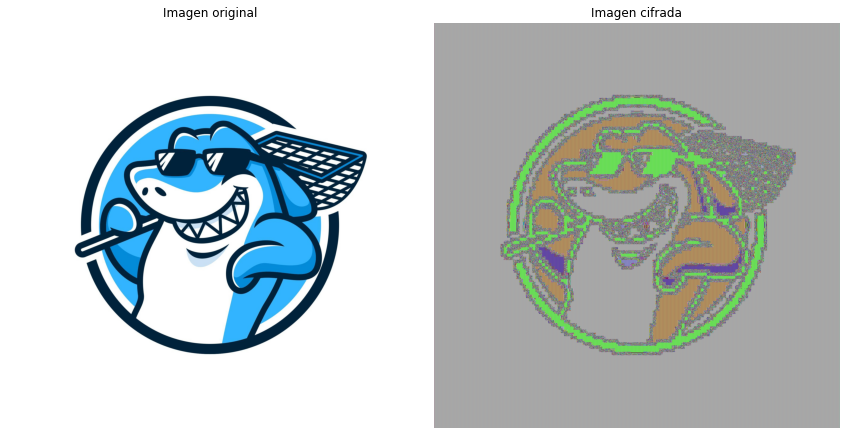

In [19]:
from PIL import Image
import numpy as np
from pynq import Overlay
import matplotlib.pyplot as plt

BLOCK_SIZE = 4        # 32 bits = 4 bytes
MAX_BLOCKS = 32    # límite de la IP
KEY = 0x0123456789ABCDEF
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_32/cifrado_paralelo_32.bit')
ip = overlay.cifrador_paralelo_32_0

def process_image(input_path, output_path):
    # Cargar imagen
    img = Image.open(input_path).convert("RGB")
    data = np.array(img)
    flat = data.tobytes()

    # Padding si no es múltiplo de 4
    remainder = len(flat) % BLOCK_SIZE
    if remainder != 0:
        flat += b'\x00' * (BLOCK_SIZE - remainder)

    # Convertir bytes a lista
    bloques = [int(x) for x in np.frombuffer(flat, dtype=np.uint32)] #bloques = list(np.frombuffer(flat, dtype=np.uint32))
    n_total = len(bloques)

    # Procesar en chunks de MAX_BLOCKS
    cifrados = []
    for i in range(0, n_total, MAX_BLOCKS):
        chunk = bloques[i:i + MAX_BLOCKS]
        original_len = len(chunk)
        
        # Rellenar con ceros si el chunk tiene menos de 32 bloques
        if len(chunk) < MAX_BLOCKS:
            chunk += [0] * (MAX_BLOCKS - len(chunk))
            
        result = ip.cifrar_n(chunk, KEY)
        
        cifrados.extend(result[:original_len])

    # Convertir resultado a bytes
    encrypted_bytes = np.array(cifrados, dtype=np.uint32).tobytes()

    # Reconstruir imagen
    encrypted_array = np.frombuffer(encrypted_bytes, dtype=np.uint8)
    encrypted_array = encrypted_array[:data.size]
    encrypted_image = encrypted_array.reshape(data.shape)

    out_img = Image.fromarray(encrypted_image.astype(np.uint8), "RGB")
    out_img.save(output_path)

    # Visualizar las dos imágenes
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(data)
    axes[0].set_title("Imagen original")
    axes[0].axis("off")
    axes[1].imshow(encrypted_image)
    axes[1].set_title("Imagen cifrada")
    axes[1].axis("off")
    plt.tight_layout()
    plt.savefig("comparacion.png")
    plt.show()

    return out_img

salida = process_image('/home/xilinx/pynq/overlays/Ultima/imagen_test.png', '/home/xilinx/pynq/overlays/pruebas/encrypted.png')

Nonce: 0x8451cff5
Guarda el nonce para descifrar: 0x8481cff5


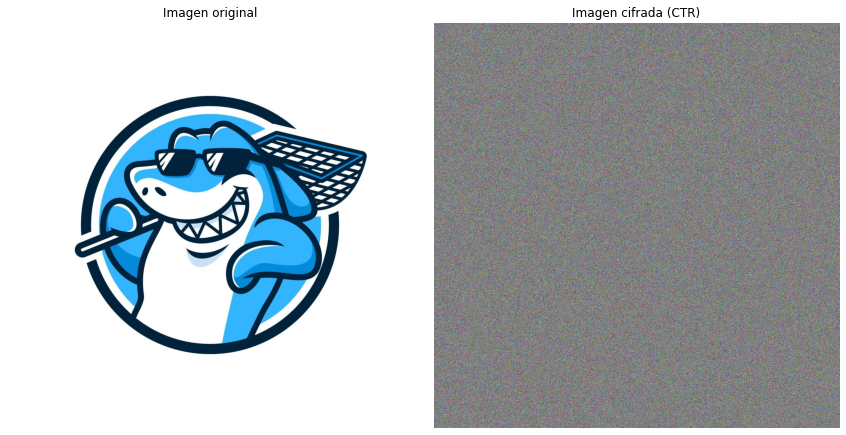

In [30]:
from PIL import Image
import numpy as np
from pynq import Overlay
import matplotlib.pyplot as plt
import random

BLOCK_SIZE = 4        # 32 bits = 4 bytes
MAX_BLOCKS = 32    # límite de la IP
KEY = 0x0123456789ABCDEF
overlay = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_32_ctr/cifrado_paralelo_32_ctr.bit')
ip = overlay.cifrador_paralelo_32_0



def process_image_ctr(input_path, output_path):
    # Cargar imagen
    img = Image.open(input_path).convert("RGB")
    data = np.array(img)
    flat = data.tobytes()

    # Padding si no es múltiplo de 4
    remainder = len(flat) % BLOCK_SIZE
    if remainder != 0:
        flat += b'\x00' * (BLOCK_SIZE - remainder)

    # Convertir bytes a lista
    bloques = [int(x) for x in np.frombuffer(flat, dtype=np.uint32)]
    n_total = len(bloques)

    # Nonce aleatorio de 16 bits — el mismo para toda la imagen
    nonce = random.randint(0, 0xFFFFFFFF)
    print("Nonce:", hex(nonce))

    # Procesar en chunks de MAX_BLOCKS
    cifrados = []
    for i in range(0, n_total, MAX_BLOCKS):
        chunk = bloques[i:i + MAX_BLOCKS]
        original_len = len(chunk)
        
        # Rellenar con ceros si el chunk tiene menos de 32 bloques
        if len(chunk) < MAX_BLOCKS:
            chunk += [0] * (MAX_BLOCKS - len(chunk))
            
        result = ip.cifrar_n(chunk, KEY, nonce)
        nonce += MAX_BLOCKS
        
        cifrados.extend(result[:original_len])

    # Convertir resultado a bytes
    encrypted_bytes = np.array(cifrados, dtype=np.uint32).tobytes()

    # Reconstruir imagen
    encrypted_array = np.frombuffer(encrypted_bytes, dtype=np.uint8)
    encrypted_array = encrypted_array[:data.size]
    encrypted_image = encrypted_array.reshape(data.shape)

    out_img = Image.fromarray(encrypted_image.astype(np.uint8), "RGB")
    out_img.save(output_path)

    # Guardar nonce para poder descifrar después
    print(f"Guarda el nonce para descifrar: {hex(nonce)}")

    # Visualizar
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(data)
    axes[0].set_title("Imagen original")
    axes[0].axis("off")
    axes[1].imshow(encrypted_image)
    axes[1].set_title("Imagen cifrada (CTR)")
    axes[1].axis("off")
    plt.tight_layout()
    plt.savefig("comparacion_ctr.png")
    plt.show()

    return out_img, nonce

img_cifrada, nonce = process_image_ctr(
    '/home/xilinx/pynq/overlays/Ultima/imagen_test.png',
    '/home/xilinx/pynq/overlays/pruebas/encrypted_ctr.png'
)

# Pruebas

## Generales

In [47]:
def comparar_resultados(resultado, expected):
    """Compara resultado con expected, verificando que TODOS los valores sean iguales"""
    if isinstance(resultado, (list, np.ndarray)):
        # Convierte a array si es lista
        arr = np.array(resultado) if isinstance(resultado, list) else resultado
        # Verifica que TODOS los elementos sean iguales a expected
        return np.all(arr == expected)
    else:
        # Valor singular
        return resultado == expected

def prueba_global(BLOCK, KEY, RESULT):
    resultados = {}
    
    # Pruebas software
    resultados['encrypt_directo'] = encrypt_directo(BLOCK, KEY)
    resultados['encrypt_lookup'] = encrypt_lookup(BLOCK, KEY)
    resultados['encrypt_sp_all_tables'] = encrypt_sp_all_tables(BLOCK, KEY)
    resultados['encrypt_sp_one_table'] = encrypt_sp_one_table(BLOCK, KEY)
    resultados['encrypt_sp_8bit'] = encrypt_sp_8bit(BLOCK, KEY)
    resultados['encrypt_bitslice'] = encrypt_bitslice([BLOCK]*32, KEY)
    
    resultados['encrypt_onfly'] = encrypt_onfly(BLOCK, KEY)
    resultados['encrypt_lookup_onfly'] = encrypt_lookup_onfly(BLOCK, KEY)
    resultados['encrypt_sp_all_tables_onfly'] = encrypt_sp_all_tables_onfly(BLOCK, KEY)
    resultados['encrypt_sp_one_table_onfly'] = encrypt_sp_one_table_onfly(BLOCK, KEY)
    resultados['encrypt_sp_8bit_onfly'] = encrypt_sp_8bit_onfly(BLOCK, KEY)
    resultados['encrypt_bitslice_onfly'] = encrypt_bitslice_onfly([BLOCK]*32, KEY)
    
    # Hardware overlays
    resultados['cifrado_basico'] = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico/cifrado_basico.bit').cifrador_basico_0.cifrar(BLOCK, KEY)
    resultados['cifrado_basico_pre'] = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_pre/cifrado_basico_pre.bit').cifrador_basico_pre_0.cifrar(BLOCK, KEY)
    
    resultados['unroll_2'] = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_2/cifrado_basico_unroll_2.bit').cifrador_basico_unro_0.cifrar(BLOCK, KEY)
    resultados['unroll_4'] = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_4/cifrado_basico_unroll_4.bit').cifrador_basico_unro_0.cifrar(BLOCK, KEY)
    resultados['unroll_8'] = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_8/cifrado_basico_unroll_8.bit').cifrador_basico_unro_0.cifrar(BLOCK, KEY)
    resultados['unroll_10'] = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_10/cifrado_basico_unroll_10.bit').cifrador_basico_unro_0.cifrar(BLOCK, KEY)
    resultados['unroll_16'] = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_16/cifrado_basico_unroll_16.bit').cifrador_basico_unro_0.cifrar(BLOCK, KEY)
    resultados['unroll_20'] = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_20/cifrado_basico_unroll_20.bit').cifrador_basico_unro_0.cifrar(BLOCK, KEY)
    resultados['unroll_31'] = Overlay('/home/xilinx/pynq/overlays/H0/cifrado_basico_unroll_31/cifrado_basico_unroll_31.bit').cifrador_basico_unro_0.cifrar(BLOCK, KEY)
    
    resultados['paralelo_4'] = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_4/cifrado_paralelo_4.bit').cifrador_paralelo_4_0.cifrar_n([BLOCK]*4, KEY)
    resultados['paralelo_8'] = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_8/cifrado_paralelo_8.bit').cifrador_paralelo_8_0.cifrar_n([BLOCK]*8, KEY)
    resultados['paralelo_16'] = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_16/cifrado_paralelo_16.bit').cifrador_paralelo_16_0.cifrar_n([BLOCK]*16, KEY)
    resultados['paralelo_32'] = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_32/cifrado_paralelo_32.bit').cifrador_paralelo_32_0.cifrar_n([BLOCK]*32, KEY)
    
    resultados['paralelo_pre_4'] = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_pre_4/cifrado_paralelo_pre_4.bit').cifrador_paralelo_pr_0.cifrar_n([BLOCK]*4, KEY)
    resultados['paralelo_pre_8'] = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_pre_8/cifrado_paralelo_pre_8.bit').cifrador_paralelo_pr_0.cifrar_n([BLOCK]*8, KEY)
    
    resultados['paralelo_stream'] = Overlay('/home/xilinx/pynq/overlays/H1/cifrado_paralelo_stream/cifrado_paralelo_stream.bit').cifrador_paralelo_st_0.cifrar_n([BLOCK]*4, KEY)
    
    overlay = Overlay('/home/xilinx/pynq/overlays/H2/cifrado_pipeline_stream/cifrado_pipeline_stream.bit')
    dma = overlay.axi_dma_0
    resultados['pipeline_1'] = overlay.cifrador_pipeline_st_0.encrypt(dma, [BLOCK]*32, KEY)
    
    overlay = Overlay('/home/xilinx/pynq/overlays/H2/cifrado_pipeline_stream_2/cifrado_pipeline_stream_2.bit')
    dma = overlay.axi_dma_0
    resultados['pipeline_2'] = overlay.cifrador_pipeline_st_0.encrypt(dma, [BLOCK]*32, KEY)
    
    overlay = Overlay('/home/xilinx/pynq/overlays/H2/cifrado_pipeline_stream_4/cifrado_pipeline_stream_4.bit')
    dma = overlay.axi_dma_0
    resultados['pipeline_4'] = overlay.cifrador_pipeline_st_0.encrypt(dma, [BLOCK]*32, KEY)
    
    resultados['serializado'] = Overlay('/home/xilinx/pynq/overlays/H3/cifrado_serial/cifrado_serial.bit').cifrador_serial_0.cifrar(BLOCK, KEY)
    
    # Validación
    correctas = []
    incorrectas = []
    
    correctas = []
    incorrectas = []

    for nombre, resultado in resultados.items():
        if comparar_resultados(resultado, RESULT):
            correctas.append(nombre)
        else:
            incorrectas.append((nombre, resultado))
    
    return {
        'correctas': correctas,
        'incorrectas': incorrectas,
        'todos_ok': len(incorrectas) == 0
    }

In [55]:
import pandas as pd
import numpy as np

# Casos de prueba
test_cases = [
    (0x01234567, 0x0123456789ABCDEF, 0xf9097518),
    (0x00000000, 0x0000000000000000, 0x2d15d21e),
    (0xFFFFFFFF, 0xFFFFFFFFFFFFFFFF, 0x459ecd3c),
]

resultados_tabla = []


for plaintext, key, expected in test_cases:
    result = prueba_global(plaintext, key, expected)
    
    resultados_tabla.append({
        'Texto Plano': f'0x{plaintext:08X}',
        'Llave': f'0x{key:016X}',
        'Cifrado': f'0x{expected:08X}',
        'Todo OK': result['todos_ok']
    })

# Crear y mostrar tabla
df = pd.DataFrame(resultados_tabla)
display(df)

,Texto Plano,Llave,Cifrado,Todo OK
0,0x01234567,0x0123456789ABCDEF,0xF9097518,True
1,0x00000000,0x0000000000000000,0x2D15D21E,True
2,0xFFFFFFFF,0xFFFFFFFFFFFFFFFF,0x459ECD3C,True


## Present

In [59]:
from pynq import Overlay
import pandas as pd
import numpy as np

def prueba_present(BLOCK, KEY, RESULT):
    resultados = {}
    resultados['Software'] = present(BLOCK, KEY)
    overlay = Overlay('/home/xilinx/pynq/overlays/present/present.bit')
    resultados['Hardware'] = overlay.present_0.cifrar(BLOCK, KEY)
    
    correctas = []
    incorrectas = []
    
    for nombre, resultado in resultados.items():
        if resultado == RESULT:
            correctas.append(nombre)
        else:
            incorrectas.append((nombre, resultado))
    
    return {
        'resultados': resultados,
        'correctas': correctas,
        'incorrectas': incorrectas,
        'todos_ok': len(incorrectas) == 0
    }

In [61]:
# Casos de prueba
test_cases = [
    (0x0000000000000000, 0x00000000000000000000, 0x5579C1387B228445),
    (0x0000000000000000, 0xFFFFFFFFFFFFFFFFFFFF, 0xE72C46C0F5945049),
    (0xFFFFFFFFFFFFFFFF, 0x00000000000000000000, 0xA112FFC72F68417B),
    (0xFFFFFFFFFFFFFFFF, 0xFFFFFFFFFFFFFFFFFFFF, 0x3333DCD3213210D2),
]

resultados_tabla = []

for plaintext, key, expected in test_cases:
    result = prueba_present(plaintext, key, expected)
    
    resultados_tabla.append({
        'Texto Plano': f'0x{plaintext:016X}',
        'Llave': f'0x{key:032X}',
        'Cifrado Esp.': f'0x{expected:016X}',
        'Todo OK': result['todos_ok']
    })
    print()

# Crear y mostrar tabla
df = pd.DataFrame(resultados_tabla)
display(df)

,Texto Plano,Llave,Cifrado Esp.,Todo OK
0,0x0000000000000000,0x00000000000000000000000000000000,0x5579C1387B228445,True
1,0x0000000000000000,0x000000000000FFFFFFFFFFFFFFFFFFFF,0xE72C46C0F5945049,True
2,0xFFFFFFFFFFFFFFFF,0x00000000000000000000000000000000,0xA112FFC72F68417B,True
3,0xFFFFFFFFFFFFFFFF,0x000000000000FFFFFFFFFFFFFFFFFFFF,0x3333DCD3213210D2,True
